# UNIVERSIDAD DE LA SALLE
## Facultad de Ingeniería | Maestría en Inteligencia Artificial
### **Proyecto Integrador: Ciencia de Datos y Machine Learning**
---

### **Entregable integrado: Fases 1, 2 y 3**
* **Título del proyecto:** Analítica predictiva para la anticipación de fallas y la planeación logística del soporte de datáfonos en campo
* **Estudiante:** Sergio Andrés Rojas Ordóñez
* **Docente:** Fabián Camilo Castro Riveros
* **Grupo:** Grupo 2
* **Fuente de datos:** repositorio sergiorojas-oss/Proyecto_CIENCIA_DE_DATOS_G2

### **Nota sobre la naturaleza de los datos**

El conjunto de datos utilizado en este proyecto es sintético. Se construyó a partir de una recreación de la operación real de soporte técnico de datáfonos en campo, conservando su estructura: los modelos de terminal, las tecnologías de conectividad, los tipos de falla, los repuestos, las ciudades de cobertura y el ciclo de vida de los tickets. Para proteger la confidencialidad de la información de la operación, los registros fueron alterados: los comercios, técnicos, documentos, direcciones y seriales se reemplazaron por códigos anónimos, y los volúmenes, fechas y combinaciones de variables se generaron de forma que no permitan identificar casos reales. Por esta razón, los resultados de este cuaderno son válidos como ejercicio metodológico y como prueba de concepto, y su aplicación en la operación requiere validarlos previamente con datos reales.

## Estructura del Cuaderno y Correspondencia con la Guía

### Fase 1: Fundamentación, Planteamiento y EDA
* **Contexto, revisión crítica, pregunta principal y 3 secundarias:** Secciones 1.1 – 1.3
* **Objetivos SMART (1 general y 3 específicos):** Sección 1.4
* **Ficha técnica y diccionario de datos:** Sección 2
* **EDA univariado (tendencia central, dispersión, asimetría, curtosis, frecuencias):** Secciones 3.2 – 3.4
* **EDA bivariado y multivariado (Spearman, dispersión, chi-cuadrado):** Secciones 3.5 – 3.7
* **Diagnóstico de calidad (faltantes, atípicos IQR/Z-score, duplicados, incoherencias):** Sección 3.8

### Fase 2: Preparación, Ingeniería de Atributos y Modelos Base
* **Duplicados, incoherencias y mecanismo de faltantes (MCAR, MAR, MNAR):** Secciones 4.1 – 4.3
* **Imputación justificada y tratamiento de atípicos:** Secciones 4.4, 5.2
* **Variables derivadas del dominio:** Sección 5.1
* **Auditoría de fuga, codificación y escalamiento ajustado solo con entrenamiento:** Secciones 5.3, 6.3
* **Partición estratificada 70/15/15 y revisión del desbalance:** Secciones 6.1 – 6.2
* **Modelos base (Dummy, Regresión Logística, Regresión Lineal Simple):** Sección 7

### Fase 3: Modelado Avanzado, Pronóstico, Clustering e Interpretabilidad
* **Regresión regularizada (ElasticNet) y ensamble (Gradient Boosting):** Secciones 8.1 – 8.2
* **Pronóstico de demanda semanal (extensión proactiva):** Sección 8.3
* **Clasificación con dos algoritmos (Árbol de Decisión y Random Forest):** Secciones 9.1 – 9.3
* **Perceptrón multicapa en PyTorch con curva de pérdida:** Sección 9.4
* **Búsqueda de hiperparámetros con validación cruzada:** Secciones 8.1, 9.1, 9.3
* **Interpretabilidad (importancia por permutación y SHAP):** Sección 10
* **K-Means (codo y silueta) y clustering jerárquico aglomerativo:** Sección 11
* **Evaluación final en prueba, impacto operativo y conclusiones:** Secciones 12 – 14


---
# PARTE I · FASE 1: PLANTEAMIENTO DEL PROBLEMA, DESCRIPCIÓN Y EDA

# 1. Formulación del Problema y Objetivos

## 1.1 **Contexto del Dominio**

Los datáfonos son el punto de contacto entre el comercio y la red transaccional. Cuando un terminal falla, el comercio deja de recibir pagos con tarjeta hasta que un técnico resuelve el incidente. La operación de soporte en campo tiene tres recursos limitados: técnicos, tiempo y repuestos. Hoy esos recursos se gestionan de forma reactiva: el ticket se abre, se despacha un técnico y solo en la visita se sabe si la falla requiere un repuesto. Esto genera visitas repetidas, inventario mal distribuido entre ciudades y tiempos de resolución difíciles de comprometer con el comercio.

El valor de la analítica en este dominio está en **mover decisiones hacia el momento de apertura del ticket**: saber, antes de salir a campo, qué falla es más probable, si la visita necesitará repuesto y cuánto tardará su resolución. Además, permite saber cuánta demanda llegará la próxima semana a cada ciudad y qué comercios conviene atender de forma preventiva.

## 1.2 **Planteamiento Inicial**

La Fase 1 planteó predecir TIPO_PROBLEMA a partir de NOMBRE_EQUIPO con una precisión mínima del 85 % y un F1 superior a 0,80. Al revisar este planteamiento a la luz de los datos encontramos tres limitaciones:

1. **La meta no es alcanzable con la información disponible.** En la versión vigente del dataset, la V de Cramér entre NOMBRE_EQUIPO y TIPO_PROBLEMA es 0,235 (sección 3.7). El modelo de equipo condiciona la falla, pero no la determina: con 12 categorías y esa fuerza de asociación, ningún clasificador puede acercarse al 85 % de exactitud. La meta se formuló sin un modelo base que la respaldara.
2. **El enfoque era reactivo.** Clasificar la falla después de reportada describe el problema pero no cambia la operación. Las decisiones que sí cambian la operación son anticipatorias: qué repuesto cargar, cuánto tiempo comprometer, cuántos técnicos asignar por ciudad y qué comercios visitar antes de que fallen.
3. **El objetivo de clustering no era medible.** "Reducir los tiempos de atención en un 15 %" no se puede verificar dentro del proyecto, porque requiere implementar la estrategia en campo y medir su efecto.

Además, las Fases 1  trabajaron sobre una primera versión del dataset en la que cada ticket aparecía tres veces y las variables eran independientes entre sí, lo que llevó a concluir que no había señal predictiva. El repositorio contiene hoy una segunda versión (commit 8de46d1, 11 de noviembre de 2026) con 209.160 tickets únicos y dependencias reales entre variables. Este cuaderno reconstruye todo el proceso sobre esa versión.

**Reformulación.** Orientamos el proyecto hacia una analítica **predictiva y proactiva** que responda cuatro decisiones logísticas, cada una asociada a una técnica de la guía:

| Decisión operativa | Tarea analítica | Variable objetivo |
| :--- | :--- | :--- |
| ¿Qué repuestos debe llevar el técnico? | Clasificación binaria y multiclase | `requiere_repuesto`, `TIPO_PROBLEMA` (top-3) |
| ¿Cuánto tiempo comprometer con el comercio? | Regresión | `dias_resolucion` |
| ¿Cuántos tickets llegarán por ciudad? | Regresión con rezagos (pronóstico) | Tickets por semana y ciudad |
| ¿Qué comercios priorizar en mantenimiento preventivo? | Clustering | Segmento del comercio |

## 1.3 **Preguntas de Investigación**

**Pregunta principal:** ¿En qué medida un sistema analítico construido únicamente con la información disponible al abrir un ticket (equipo, tecnología, ubicación, tipo de falla reportado, calendario e historial del comercio) puede anticipar la necesidad de repuestos, el tiempo de resolución y la demanda de soporte, y segmentar a los comercios para planear de forma proactiva la logística de campo?

**Preguntas secundarias:**
1. ¿Qué variables del terminal, de la conectividad y de la ubicación se asocian con el tipo de falla, la necesidad de repuesto y el tiempo de resolución?
2. ¿Cómo se distribuye la demanda de soporte en el tiempo y entre ciudades, y con qué error puede pronosticarse con una semana de anticipación?
3. ¿Qué segmentos de comercios emergen según su volumen y su perfil de fallas, y qué estrategia de mantenimiento preventivo corresponde a cada uno?

## 1.4 **Objetivos SMART**

Las metas se definen en relación con los modelos base de la sección 7 y con umbrales de utilidad operativa, de modo que cada una sea verificable en el conjunto de prueba.

**Objetivo general.** Desarrollar un sistema de analítica predictiva y no supervisada sobre los 209.160 tickets únicos registrados entre enero de 2025 y octubre de 2026. El sistema debe anticipar la necesidad de repuestos, el tiempo de resolución y la demanda semanal de soporte por ciudad, y segmentar a los 900 comercios. Será el insumo del dashboard de la Fase 4.

**Objetivos específicos.**
1. **Inventario en campo.** Entrenar y comparar al menos dos algoritmos de clasificación y un perceptrón multicapa para predecir si una visita requiere repuesto, con AUC-ROC ≥ 0,80 y F1 ≥ 0,75 en prueba. Complementarlo con un clasificador del tipo de falla cuya exactitud top-3 supere en al menos 15 puntos porcentuales a la referencia por frecuencias, para conformar el kit del técnico.
2. **Capacidad y tiempos.** Estimar los días de resolución con una regresión regularizada y un ensamble, reduciendo el MAE(Error Absoluto Medi) en prueba al menos un 15 % frente al modelo Dummy. Pronosticar la demanda semanal por ciudad con un MAE inferior al del pronóstico ingenuo (repetir la semana anterior).
3. **Mantenimiento preventivo.** Segmentar los 900 comercios con K-Means (clustering (agrupamiento))(seleccionando *k* por el método del codo y el coeficiente de silueta) y con clustering jerárquico. La meta es obtener una silueta ≥ 0,25 y traducir cada segmento en una estrategia de mantenimiento diferenciada.

# 2. Ficha Técnica del Dataset

* **Nombre:** Solicitudes de Soporte y Operaciones de Datáfonos (Solicitudes Soportes.csv)
* **Repositorio de origen:** GitHub, repositorio académico del Grupo 2
* **URL de acceso:** https://github.com/sergiorojas-oss/Proyecto_CIENCIA_DE_DATOS_G2 (archivo Solicitudes Soportes.zip)
* **Versión analizada:** commit 8de46d135e859d9c0d5bc70f1d46c1d145db4e6d, publicado el 11 de noviembre de 2026
* **Fecha de extracción:** 11 de noviembre de 2026
* **Licencia:** Creative Commons Atribución (CC-BY), uso académico abierto
* **Cobertura temporal:** tickets creados entre el 1 de enero de 2025 y el 28 de octubre de 2026
* **Volumen:** 210.000 registros y 28 columnas (209.160 tickets únicos después de la limpieza)
* **Naturaleza de los datos:** registros operativos anonimizados; los comercios, técnicos, documentos y direcciones aparecen codificados

### **Diccionario de Datos**

| Columna | Tipo de variable | Descripción funcional | Rango / valores permitidos | Uso |
| :--- | :--- | :--- | :--- | :--- |
| `CENTRO_Y_AL` | Cualitativa nominal | Centro y almacén que despacha el servicio | 15 códigos (ej. 1000-078); cada uno pertenece a una sola ciudad | Entrada |
| `Estado` | Cualitativa nominal | Estado del ticket | Cerrado, En Proceso, Abierto | Diagnóstico |
| `ID_Llamada` | Identificador | Número único de la llamada de soporte | Entero 1.400.000 – 1.609.159 | Control de duplicados |
| `Material_Servi_1` a `_4` | Cualitativa nominal | Repuestos usados en la visita | Pin pad, SIM card, Cable de red, Batería Li-Ion, Teclado, Cabezal Térmico, Cargador | Construcción de objetivos |
| `NOMBRE_EQUIPO` | Cualitativa nominal | Modelo del terminal POS | 10 modelos (ej. POS DX4000 INGENICO, N6 ANDROID 10) | Entrada |
| `Serial_Actuac`, `Serial_Equipo` | Identificador | Seriales del terminal | ~3.200 valores alfanuméricos | Excluidas |
| `ID_SERVICE`, `ESTADO`, `ID_Codigo_AN` | Identificador | Códigos internos del sistema | Enteros consecutivos | Excluidas |
| `TIPO_PROBLEMA` | Cualitativa nominal | Tipo de falla reportada | 12 categorías (ej. Sin señal o nivel bajo, Falla del pin) | Objetivo y entrada |
| `ESTADO_ACT` | Cualitativa nominal | Descripción extendida de la falla | 12 textos, equivalentes uno a uno con `TIPO_PROBLEMA` | Excluida (fuga) |
| `CATEGORIA` | Cualitativa nominal | Categoría del servicio | Constante: Soporte | Excluida |
| `CREADO_EN` | Temporal | Fecha de apertura | ISO AAAA-MM-DD, ene 2025 – oct 2026 | Variables derivadas |
| `FINALIZADO` | Temporal | Fecha de cierre | D/MM/AAAA; vacía si el ticket no se ha cerrado | Variables derivadas |
| `CC` | Identificador sensible | Documento del contacto | 900 valores | Excluida |
| `CIUDAD` | Cualitativa nominal | Ciudad del comercio | 6 ciudades | Entrada |
| `SECCIONAL` | Cualitativa nominal | Seccional | Equivalente uno a uno con `CIUDAD` | Excluida |
| `DIRECCION` | Cualitativa nominal | Dirección del comercio | 900 valores | Excluida |
| `USUARIO` | Cualitativa nominal | Comercio que reporta | 900 comercios (CLIENTE_n) | Agregación y clustering |
| `Tecnico` | Cualitativa nominal | Técnico asignado | 8 técnicos | Entrada (regresión) |
| `TECNOLOGIA` | Cualitativa nominal | Conectividad del terminal | GPRS, DIAL-LAN, Wi-Fi, OTROS | Entrada |
| `i.externalid` | Identificador | Código externo | 60 valores | Excluida |
| `i.groupCode` | Sin datos | Campo vacío | 100 % faltante | Excluida |
| `i.name` | Cualitativa nominal | Nombre del equipo | Idéntica a `NOMBRE_EQUIPO` | Excluida |

# 3. Análisis Exploratorio de Datos (EDA)

## 3.1 **Configuración del Entorno y Carga de Datos**

Instalamos la versión de scikit-learn con la que se validó el cuaderno y la librería SHAP; luego importamos las librerías y fijamos una semilla única para que particiones, búsquedas de hiperparámetros y algoritmos estocásticos sean reproducibles. La URL del dataset apunta a un commit específico del repositorio, no a la rama principal. Así, cualquier ejecución futura analiza exactamente los mismos datos aunque el repositorio se actualice.

In [2]:
# versión de scikit-learn fijada para reproducir exactamente los resultados; shap para la interpretabilidad
%pip install -q scikit-learn==1.9.1 shap

In [3]:
import os
import time
import zipfile
import warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid', palette='deep')

SEMILLA = 42
np.random.seed(SEMILLA)

# versión del dataset fijada al commit del repositorio para garantizar reproducibilidad
COMMIT_DATASET = '8de46d135e859d9c0d5bc70f1d46c1d145db4e6d'
URL_DATASET = ('https://github.com/sergiorojas-oss/Proyecto_CIENCIA_DE_DATOS_G2/raw/'
               f'{COMMIT_DATASET}/Solicitudes%20Soportes.zip')
RUTA_ZIP = 'Solicitudes_Soportes.zip'
RUTA_CSV = 'Solicitudes Soportes.csv'
FECHA_EXTRACCION = pd.Timestamp('2026-11-11')

print('Librerías cargadas. Semilla:', SEMILLA)

Librerías cargadas. Semilla: 42


In [4]:
if not os.path.exists(RUTA_CSV):
    print('Descargando el dataset desde GitHub (commit fijado)...')
    urllib.request.urlretrieve(URL_DATASET, RUTA_ZIP)
    with zipfile.ZipFile(RUTA_ZIP, 'r') as archivo_zip:
        archivo_zip.extractall('.')

df_original = pd.read_csv(RUTA_CSV, sep=';', low_memory=False)
df = df_original.copy()

print(f'Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas')
print(f'Memoria en uso: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB')
display(df.head(3))

Descargando el dataset desde GitHub (commit fijado)...
Dimensiones: 210,000 filas x 28 columnas
Memoria en uso: 259.2 MB


,CENTRO_Y_AL,Estado,ID_Llamada,Material_Servi_1,Material_Servi_2,Material_Servi_3,Material_Servi_4,NOMBRE_EQUIPO,Serial_Actuac,Serial_Equipo,ID_SERVICE,TIPO_PROBLEMA,ESTADO,ESTADO_ACT,CATEGORIA,CREADO_EN,FINALIZADO,ID_Codigo_AN,CC,CIUDAD,SECCIONAL,DIRECCION,USUARIO,Tecnico,TECNOLOGIA,i.externalid,i.groupCode,i.name
0,1000-078,Cerrado,1400000,Batería Li-Ion,Cargador,NaN,NaN,N86 INALAMBRICO ANDROID,0008C608,EQ-699BAB,537748,Datafono no enciende,3907275,Datáfono no enciende,Soporte,2025-01-01T,13/02/2025,1424219,99269754,MANIZALES,Manizales,Carrera 58 # 23-61,CLIENTE_428,IDARRAGAHI,Wi-Fi,80000039,NaN,N86 INALAMBRICO ANDROID
1,1000-078,Cerrado,1400001,SIM card,NaN,NaN,NaN,POS DX4000 INGENICO,0006CBFC,NaN,327708,POS no carga,3926360,POS no carga GPRS,Soporte,2025-01-01T,6/01/2025,1404404,91778297,MANIZALES,Manizales,CLL 76 # 39-51,CLIENTE_648,RIOS ABADD,GPRS,80000005,NaN,POS DX4000 INGENICO
2,1003-035,Cerrado,1400002,NaN,NaN,NaN,NaN,POS DX4000 INGENICO,000978B1,EQ-89E142,109192,SOPORTE PROACTIVO,3910191,Soporte Proactivo,Soporte,2025-01-01T,4/01/2025,1447906,93725295,BARRANQUI,Barranquilla,Carrera 44 # 84-72,CLIENTE_863,SALGADO VA,GPRS,80000010,NaN,POS DX4000 INGENICO


El archivo tiene 210.000 registros y 28 columnas, y ocupa unos 260 MB en memoria. Las primeras filas muestran la estructura típica de un ticket: datos del terminal (NOMBRE_EQUIPO, seriales, TECNOLOGIA), del comercio (USUARIO, CIUDAD, DIRECCION), de la falla (TIPO_PROBLEMA, ESTADO_ACT), del ciclo de vida (CREADO_EN, FINALIZADO, Estado) y de los repuestos usados (Material_Servi_1 a _4).

## 3.2 **Naturaleza de las Columnas Numéricas**

Antes de calcular estadísticos descriptivos verificamos si las columnas numéricas del archivo son medidas o identificadores. Un identificador consecutivo tiene una distribución uniforme, y eso se reconoce por una asimetría cercana a 0 y una curtosis cercana a −1,2.

In [5]:
print('=== COLUMNAS NUMÉRICAS DEL ARCHIVO ORIGINAL ===')
columnas_numericas = df.select_dtypes(include='number').columns.drop('i.groupCode')
resumen_ids = pd.DataFrame({
    'Valores únicos': df[columnas_numericas].nunique(),
    '% únicos': (df[columnas_numericas].nunique() / len(df) * 100).round(1),
    'Asimetría': df[columnas_numericas].skew().round(3),
    'Curtosis': df[columnas_numericas].kurtosis().round(3),
})
display(resumen_ids)

=== COLUMNAS NUMÉRICAS DEL ARCHIVO ORIGINAL ===


,Valores únicos,% únicos,Asimetría,Curtosis
ID_Llamada,209160,99.6,-0.000,-1.199
ID_SERVICE,188752,89.9,-0.001,-1.200
ESTADO,49207,23.4,-0.004,-1.201
ID_Codigo_AN,49249,23.5,0.005,-1.201
CC,900,0.4,0.007,-1.167
i.externalid,60,0.0,0.001,-1.189


Las seis columnas numéricas tienen asimetría prácticamente nula y curtosis entre −1,17 y −1,20, la firma de una distribución uniforme. Son códigos (ID_Llamada es único en el 99,6 % de las filas; CC tiene 900 valores, uno por comercio) y su media o su desviación estándar no tienen interpretación. Por eso las variables cuantitativas del análisis se construyen a partir de las fechas, los repuestos y la agregación por comercio (sección 3.4).

## 3.3 **Análisis Univariado de las Variables Cualitativas**

Las tablas de frecuencia absoluta, relativa y acumulada describen la composición de la operación y anticipan el balance de las clases para el modelado.

In [6]:
print('=== TABLAS DE FRECUENCIA DE LAS VARIABLES CUALITATIVAS ===')
for columna in ['TIPO_PROBLEMA', 'NOMBRE_EQUIPO', 'TECNOLOGIA', 'CIUDAD', 'Tecnico', 'Estado']:
    tabla = pd.DataFrame({
        'Frecuencia': df[columna].value_counts(dropna=False),
        '%': (df[columna].value_counts(dropna=False, normalize=True) * 100).round(2),
    })
    tabla['% acumulado'] = tabla['%'].cumsum().round(2)
    print(f'\n--- {columna} ({df[columna].nunique()} categorías) ---')
    display(tabla)

=== TABLAS DE FRECUENCIA DE LAS VARIABLES CUALITATIVAS ===

--- TIPO_PROBLEMA (12 categorías) ---


,Frecuencia,%,% acumulado
TIPO_PROBLEMA,,,
Sin senal o nivel bajo,37837,18.02,18.02
Falla del pin,23216,11.06,29.08
Cable de red,21826,10.39,39.47
POS no carga,18745,8.93,48.40
Datafono no enciende,17032,8.11,56.51
Tamper bloqueo,16812,8.01,64.52
Mantenimiento preventivo,16057,7.65,72.17
Dano o bloqueo,15131,7.21,79.38
Reconfiguracion de IP,14374,6.84,86.22



--- NOMBRE_EQUIPO (10 categorías) ---


,Frecuencia,%,% acumulado
NOMBRE_EQUIPO,,,
POS DX4000 INGENICO,36327,17.30,17.30
DATAFONO LANE 3000,29922,14.25,31.55
DATAFONOS V200C CTLS - VI,27758,13.22,44.77
DATAFONOS ICT220 - ING,26143,12.45,57.22
DATAFONOS VX520 CL - VER,24277,11.56,68.78
N86 INALAMBRICO ANDROID,19662,9.36,78.14
N6 ANDROID 10,12954,6.17,84.31
DATAFONOS V240 M - VER,11552,5.50,89.81
POS VENTA KD69,10948,5.21,95.02



--- TECNOLOGIA (4 categorías) ---


,Frecuencia,%,% acumulado
TECNOLOGIA,,,
GPRS,102092,48.62,48.62
DIAL-LAN,64786,30.85,79.47
OTROS,26746,12.74,92.21
Wi-Fi,16376,7.80,100.01


... (2 outputs left out)


--- Tecnico (8 categorías) ---


,Frecuencia,%,% acumulado
Tecnico,,,
GARCIA BETA,35438,16.88,16.88
MOYADIEGO,35318,16.82,33.70
SALGADO VA,34293,16.33,50.03
RIOS ABADD,29916,14.25,64.28
IDARRAGAHI,29767,14.17,78.45
CARVAJALJU,15684,7.47,85.92
ORTIZ GARCI,15615,7.44,93.36
GUEVARA RC,13969,6.65,100.01



--- Estado (3 categorías) ---


,Frecuencia,%,% acumulado
Estado,,,
Cerrado,179574,85.51,85.51
En Proceso,21130,10.06,95.57
NaN,8312,3.96,99.53
Abierto,984,0.47,100.00


* **TIPO_PROBLEMA** tiene 12 categorías con un desbalance moderado: "Sin señal o nivel bajo" concentra el 18,0 % de los tickets y "tarjeta rechazada" el 4,3 %. Las fallas de conectividad (sin señal, cable de red, POS no carga, reconfiguración de IP) suman cerca del 44 %.
* **NOMBRE_EQUIPO**: cinco modelos tradicionales (DX4000, Lane 3000, V200C, ICT220 y VX520) concentran el 69 % de los tickets. Los terminales Android suman el 20,5 %.
* **TECNOLOGIA**: casi la mitad de los terminales opera con GPRS (48,6 %), lo que hace de la conectividad móvil un frente crítico.
* **CIUDAD**: Bogotá concentra un tercio de la demanda (33,7 %), seguida de Medellín (19,9 %). Manizales es la de menor volumen (8,6 %).
* **Tecnico**: la carga no está repartida por igual; tres técnicos atienden cada uno cerca del 17 % y los tres de menor carga, entre 6,7 % y 7,5 %.
* **Estado**: el 85,5 % de los tickets está cerrado y el 4 % no tiene estado registrado, lo que se trata en la sección 4.

## 3.4 **Análisis Univariado de las Variables Cuantitativas**

Se construyeron cuatro variables cuantitativas con significado operativo: los días entre apertura y cierre, el número de repuestos usados por visita y, para cada ticket, el volumen de tickets y de equipos de su comercio. Para cada una calculamos medidas de tendencia central, dispersión, asimetría y curtosis.

=== VARIABLES CUANTITATIVAS DE ANÁLISIS (CÁLCULO EXPLORATORIO) ===


,n,Media,Mediana,Moda,Desv. estándar,Coef. variación,Mínimo,Máximo,Asimetría,Curtosis
dias_resolucion,183229,6.600,5.0,2.0,7.814,1.184,-29.0,262.0,4.728,69.789
num_repuestos,210000,0.642,1.0,0.0,0.683,1.063,0.0,4.0,0.793,0.326
tickets_del_comercio,210000,820.476,440.0,3494.0,837.104,1.020,8.0,3494.0,1.274,0.850
equipos_del_comercio,210000,8.817,5.0,2.0,6.910,0.784,1.0,20.0,0.401,-1.494


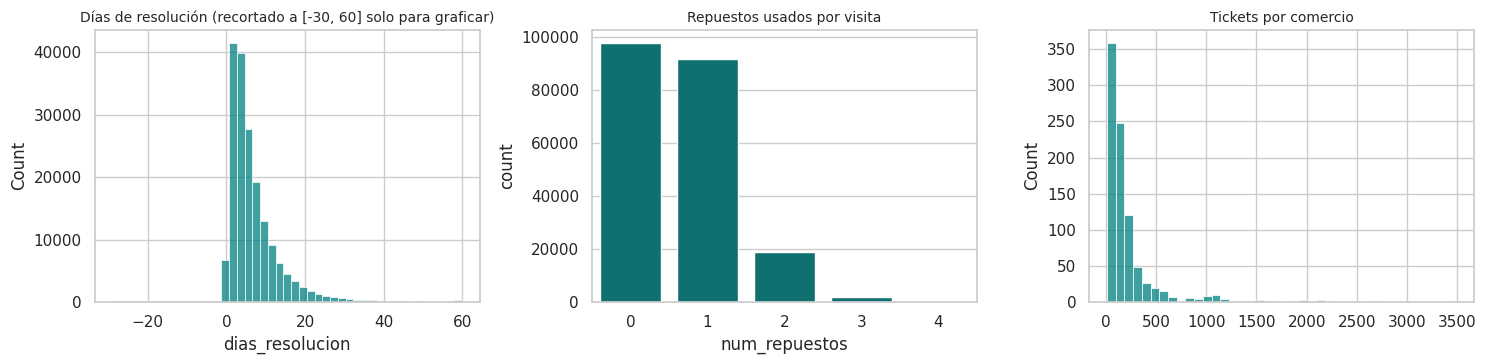

In [7]:
print('=== VARIABLES CUANTITATIVAS DE ANÁLISIS (CÁLCULO EXPLORATORIO) ===')
creado = pd.to_datetime(df['CREADO_EN'].str.rstrip('T'), format='%Y-%m-%d', errors='coerce')
finalizado = pd.to_datetime(df['FINALIZADO'], format='%d/%m/%Y', errors='coerce')
columnas_material = ['Material_Servi_1', 'Material_Servi_2', 'Material_Servi_3', 'Material_Servi_4']

exploratorio = pd.DataFrame({
    'dias_resolucion': (finalizado - creado).dt.days,
    'num_repuestos': df[columnas_material].notna().sum(axis=1),
    'tickets_del_comercio': df.groupby('USUARIO')['ID_Llamada'].transform('count'),
    'equipos_del_comercio': df.groupby('USUARIO')['Serial_Actuac'].transform('nunique'),
})

def resumen_descriptivo(datos):
    return pd.DataFrame({
        'n': datos.count(),
        'Media': datos.mean(),
        'Mediana': datos.median(),
        'Moda': datos.mode().iloc[0],
        'Desv. estándar': datos.std(),
        'Coef. variación': datos.std() / datos.mean(),
        'Mínimo': datos.min(),
        'Máximo': datos.max(),
        'Asimetría': datos.skew(),
        'Curtosis': datos.kurtosis(),
    }).round(3)

display(resumen_descriptivo(exploratorio))

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(exploratorio['dias_resolucion'].clip(-30, 60), bins=45, ax=ejes[0], color='teal')
ejes[0].set_title('Días de resolución (recortado a [-30, 60] solo para graficar)', fontsize=10)
sns.countplot(x=exploratorio['num_repuestos'], ax=ejes[1], color='teal')
ejes[1].set_title('Repuestos usados por visita', fontsize=10)
sns.histplot(df.groupby('USUARIO').size(), bins=40, ax=ejes[2], color='teal')
ejes[2].set_title('Tickets por comercio', fontsize=10)
plt.tight_layout()
plt.show()

* **dias_resolucion** tiene media de 6,6 días y mediana de 5, con una asimetría de 4,73 y una curtosis de 69,8. Es una distribución con cola derecha muy larga: la mayoría de los tickets se resuelve en una semana, pero algunos tardan meses (máximo de 262 días). El mínimo de −29 días revela cierres registrados antes de la apertura, una incoherencia que se trata en la sección 4.2.
* **num_repuestos**: la moda es 0 y la media 0,64. Casi la mitad de las visitas no usa repuestos y muy pocas usan más de dos.
* **tickets_del_comercio** tiene un coeficiente de variación de 1,02 y una mediana (440) muy por debajo de la media (820). Pocos comercios generan la mayor parte de la demanda, lo que es relevante para la segmentación.

## 3.5 **Comportamiento Temporal de la Demanda**

La planeación de técnicos depende del patrón temporal de la demanda. Analizamos el volumen diario (diagrama de dispersión), mensual y por día de la semana.

=== COMPORTAMIENTO TEMPORAL DE LA DEMANDA DE SOPORTE ===
Rango de fechas: 2025-01-01 a 2026-10-28
Tickets por día: media 315.3, varianza 6037.4 (razón varianza/media = 19.1)


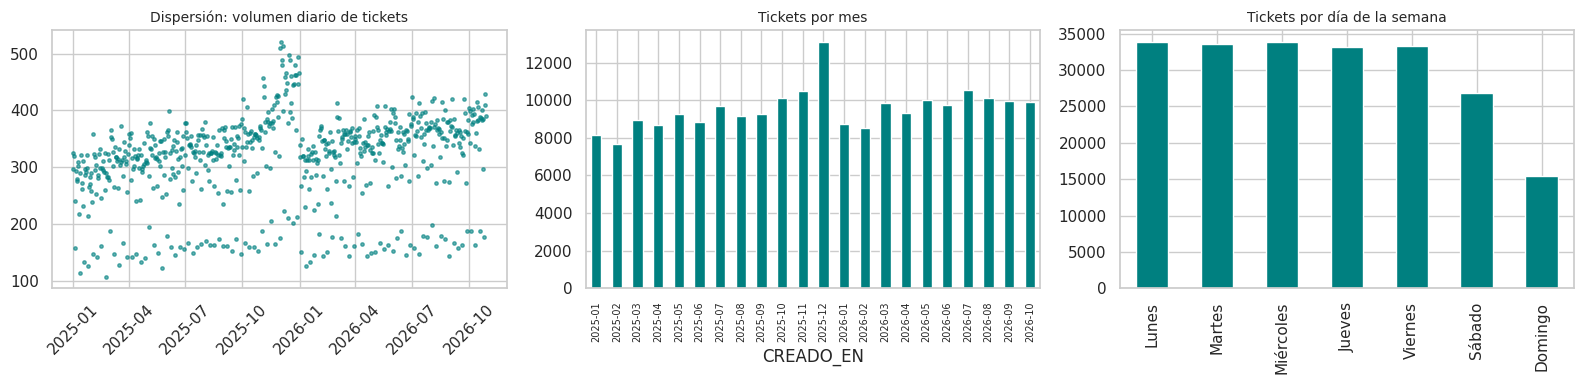

In [8]:
print('=== COMPORTAMIENTO TEMPORAL DE LA DEMANDA DE SOPORTE ===')
serie_diaria = creado.value_counts().sort_index()
serie_mensual = creado.dt.to_period('M').value_counts().sort_index()
dias_nombre = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
por_dia_semana = creado.dt.dayofweek.value_counts().sort_index()
por_dia_semana.index = dias_nombre

print(f'Rango de fechas: {creado.min().date()} a {creado.max().date()}')
print(f'Tickets por día: media {serie_diaria.mean():.1f}, varianza {serie_diaria.var():.1f} '
      f'(razón varianza/media = {serie_diaria.var() / serie_diaria.mean():.1f})')

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
ejes[0].scatter(serie_diaria.index, serie_diaria.values, s=6, alpha=0.6, color='teal')
ejes[0].set_title('Dispersión: volumen diario de tickets', fontsize=10)
ejes[0].tick_params(axis='x', rotation=45)
serie_mensual.plot(kind='bar', ax=ejes[1], color='teal')
ejes[1].set_title('Tickets por mes', fontsize=10)
ejes[1].tick_params(axis='x', rotation=90, labelsize=7)
por_dia_semana.plot(kind='bar', ax=ejes[2], color='teal')
ejes[2].set_title('Tickets por día de la semana', fontsize=10)
plt.tight_layout()
plt.show()

* La razón varianza/media del volumen diario es 19,1. En un proceso de llegadas puramente aleatorio (Poisson) sería cercana a 1, así que la demanda está **sobredispersa**: hay factores sistemáticos que la hacen subir y bajar.
* **Estacionalidad semanal:** cada día hábil acumula cerca de 33.500 tickets en el periodo; el sábado la demanda cae un 20 % y el domingo, más de la mitad. La banda inferior del diagrama de dispersión corresponde a los domingos.
* **Estacionalidad anual y tendencia:** diciembre de 2025 fue el pico del periodo (13.027 tickets), coherente con la temporada de mayor uso de datáfonos. Además, en casi todos los meses el volumen de 2026 supera al del mismo mes de 2025, lo que indica una tendencia creciente.

Estos patrones justifican incluir variables de calendario en los modelos y construir un pronóstico de demanda con rezagos (sección 8.3).

## 3.6 **Correlación entre Variables Cuantitativas (Spearman)**

Usamos el coeficiente de Spearman porque las variables son asimétricas y algunas son discretas. Spearman mide relaciones monótonas sin suponer normalidad ni linealidad.

=== CORRELACIÓN DE SPEARMAN ENTRE VARIABLES CUANTITATIVAS ===


,dias_resolucion,num_repuestos,tickets_del_comercio,equipos_del_comercio,mes,dia_semana
dias_resolucion,1.000,0.498,-0.032,-0.048,-0.037,0.063
num_repuestos,0.498,1.000,0.074,0.080,-0.016,-0.011
tickets_del_comercio,-0.032,0.074,1.000,0.863,-0.003,0.003
equipos_del_comercio,-0.048,0.080,0.863,1.000,-0.001,0.001
mes,-0.037,-0.016,-0.003,-0.001,1.000,-0.012
dia_semana,0.063,-0.011,0.003,0.001,-0.012,1.000


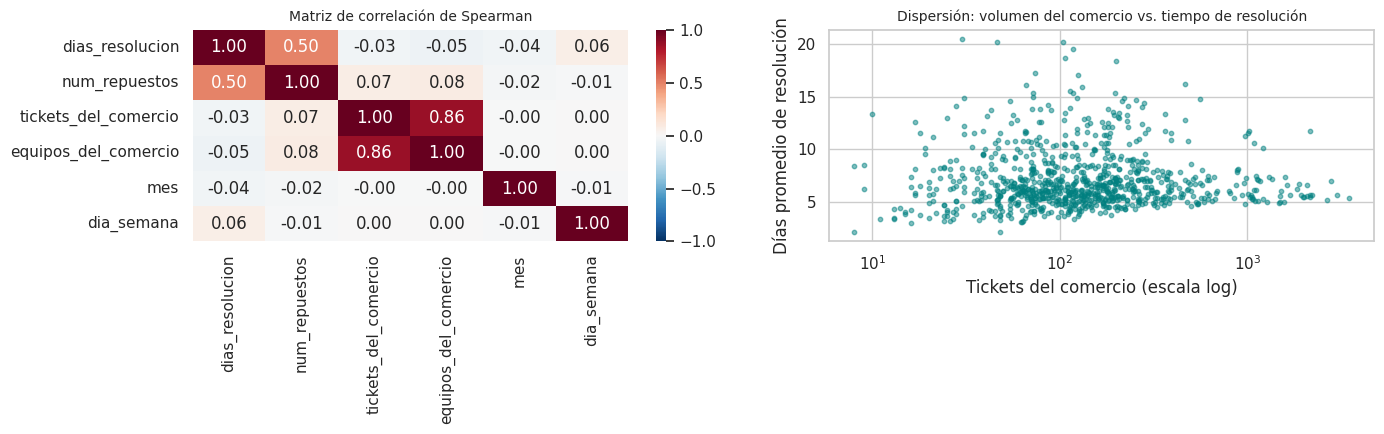

In [9]:
print('=== CORRELACIÓN DE SPEARMAN ENTRE VARIABLES CUANTITATIVAS ===')
cuantitativas = exploratorio.assign(mes=creado.dt.month, dia_semana=creado.dt.dayofweek)
cuantitativas = cuantitativas[cuantitativas['dias_resolucion'] >= 0]
matriz_spearman = cuantitativas.corr(method='spearman')
display(matriz_spearman.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(matriz_spearman, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ejes[0])
ejes[0].set_title('Matriz de correlación de Spearman', fontsize=10)
por_comercio = df.assign(dias=exploratorio['dias_resolucion'].where(exploratorio['dias_resolucion'] >= 0)) \
                 .groupby('USUARIO').agg(tickets=('ID_Llamada', 'count'), dias_promedio=('dias', 'mean'))
ejes[1].scatter(por_comercio['tickets'], por_comercio['dias_promedio'], s=10, alpha=0.5, color='teal')
ejes[1].set_xscale('log')
ejes[1].set_xlabel('Tickets del comercio (escala log)')
ejes[1].set_ylabel('Días promedio de resolución')
ejes[1].set_title('Dispersión: volumen del comercio vs. tiempo de resolución', fontsize=10)
plt.tight_layout()
plt.show()

* La correlación más relevante para el negocio es la de **dias_resolucion con num_repuestos (ρ = 0,50)**: las visitas que requieren repuestos tardan más en cerrarse. Saber de antemano si una visita necesitará repuesto es, entonces, también una forma de anticipar su duración.
* tickets_del_comercio y equipos_del_comercio están muy correlacionadas (ρ = 0,86): los comercios con más terminales generan más tickets. En el clustering ambas se transforman y se interpretan juntas.
* El volumen del comercio no se relaciona con el tiempo de resolución (ρ = −0,03). El diagrama de dispersión lo confirma: comercios grandes y pequeños tienen tiempos promedio similares, entre 5 y 10 días.
* Mes y día de la semana tienen correlaciones lineales casi nulas con las demás variables. Su efecto es cíclico (sección 3.5) y por eso se codifican con seno y coseno en la sección 5.

## 3.7 **Asociación entre Variables Cualitativas (Chi-cuadrado y V de Cramér)**

La prueba chi-cuadrado contrasta la hipótesis nula de independencia entre dos variables categóricas. Con 209.000 registros casi cualquier diferencia resulta estadísticamente significativa, por lo que acompañamos cada prueba con la **V de Cramér**, que mide la fuerza de la asociación entre 0 (independencia) y 1 (dependencia total).

=== ASOCIACIÓN ENTRE VARIABLES CUALITATIVAS (CHI-CUADRADO Y V DE CRAMÉR) ===
Prueba de independencia de cada variable frente a TIPO_PROBLEMA:


,Variable,Chi-cuadrado,gl,p-value,V de Cramér
1,TECNOLOGIA,108635.5,33,0.00e+00,0.415
0,NOMBRE_EQUIPO,104272.8,99,0.00e+00,0.235
2,CIUDAD,11577.8,55,0.00e+00,0.105
4,CENTRO_Y_AL,13481.0,165,0.00e+00,0.076
3,Tecnico,5351.5,77,0.00e+00,0.060


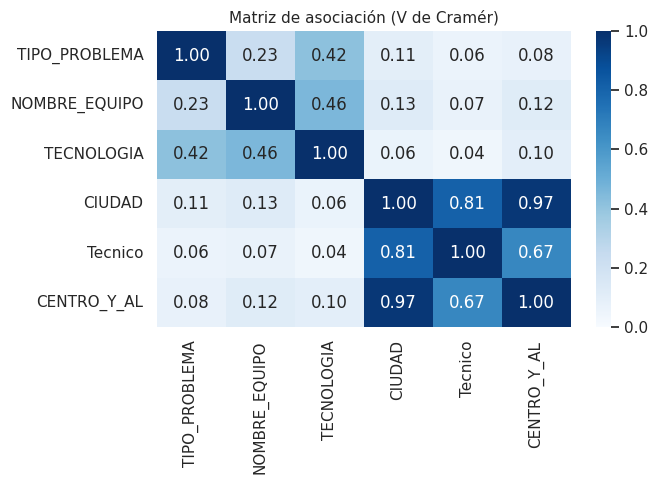

In [10]:
def v_cramer(x, y):
    """Devuelve la V de Cramér, el estadístico chi-cuadrado, los grados de libertad y el p-value."""
    tabla = pd.crosstab(x, y)
    chi2, p, gl, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    menor = min(tabla.shape) - 1
    v = np.sqrt(chi2 / (n * menor)) if menor > 0 else 0.0
    return v, chi2, gl, p


print('=== ASOCIACIÓN ENTRE VARIABLES CUALITATIVAS (CHI-CUADRADO Y V DE CRAMÉR) ===')
cualitativas = ['TIPO_PROBLEMA', 'NOMBRE_EQUIPO', 'TECNOLOGIA', 'CIUDAD', 'Tecnico', 'CENTRO_Y_AL']
datos_cual = df[cualitativas].fillna('Sin registro')
matriz_v = pd.DataFrame(1.0, index=cualitativas, columns=cualitativas)
for i, a in enumerate(cualitativas):
    for b in cualitativas[i + 1:]:
        v = v_cramer(datos_cual[a], datos_cual[b])[0]
        matriz_v.loc[a, b] = matriz_v.loc[b, a] = v

pruebas = []
for variable in cualitativas[1:]:
    v, chi2, gl, p = v_cramer(datos_cual[variable], datos_cual['TIPO_PROBLEMA'])
    pruebas.append({'Variable': variable, 'Chi-cuadrado': round(chi2, 1), 'gl': gl,
                    'p-value': f'{p:.2e}', 'V de Cramér': round(v, 3)})
print('Prueba de independencia de cada variable frente a TIPO_PROBLEMA:')
display(pd.DataFrame(pruebas).sort_values('V de Cramér', ascending=False))

plt.figure(figsize=(7, 5))
sns.heatmap(matriz_v, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Matriz de asociación (V de Cramér)', fontsize=11)
plt.tight_layout()
plt.show()

* Todas las pruebas rechazan la independencia (p-value ≈ 0), pero la V de Cramér permite ordenarlas por relevancia práctica. **TECNOLOGIA es la variable más asociada con el tipo de falla (V = 0,415)**, seguida de NOMBRE_EQUIPO (0,235). Es una relación esperable: un terminal GPRS falla por señal y uno DIAL-LAN por cable de red.
* CIUDAD (0,105), CENTRO_Y_AL (0,076) y Tecnico (0,060) tienen asociaciones débiles con el tipo de falla.
* Hay **redundancia geográfica**: CIUDAD y CENTRO_Y_AL tienen V = 0,97 (cada centro pertenece a una ciudad) y CIUDAD y Tecnico V = 0,81 (los técnicos atienden zonas fijas). Esto se considera al escoger las entradas de cada modelo.
* Con una V máxima de 0,415, el tipo exacto de falla solo es parcialmente predecible. Esto respalda la revisión del objetivo original (sección 1.2) y el uso de la exactitud top-3 como métrica operativa.

## 3.8 **Diagnóstico de Calidad de Datos**

Cuantificamos los datos faltantes, los duplicados, las incoherencias temporales y los valores atípicos (regla IQR: fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR; Z-score: más de 3 desviaciones estándar de la media).

In [11]:
print('=== DIAGNÓSTICO DE CALIDAD DE DATOS ===')
faltantes = pd.DataFrame({'Faltantes': df.isna().sum(), '% faltante': (df.isna().mean() * 100).round(2)})
print('1) Porcentaje de datos faltantes por variable:')
display(faltantes[faltantes['Faltantes'] > 0].sort_values('% faltante', ascending=False))

print(f"2) Filas duplicadas exactas: {df.duplicated().sum():,}")
print(f"   ID_Llamada repetidos:     {df['ID_Llamada'].duplicated().sum():,}")

print(f"3) Tickets cerrados antes de abrirse: {(exploratorio['dias_resolucion'] < 0).sum():,}")
print(f"   Fechas de creación posteriores a la extracción: {(creado > FECHA_EXTRACCION).sum():,}")


def contar_atipicos(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera_iqr = ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()
    fuera_z = (np.abs(stats.zscore(serie)) > 3).sum()
    return pd.Series({'Q1': q1, 'Q3': q3, 'Límite superior IQR': q3 + 1.5 * iqr,
                      'Atípicos IQR': fuera_iqr, '% IQR': round(fuera_iqr / len(serie) * 100, 2),
                      'Atípicos Z>3': fuera_z, '% Z': round(fuera_z / len(serie) * 100, 2)})


print('4) Valores atípicos (regla IQR y Z-score):')
display(exploratorio.apply(contar_atipicos).T)

=== DIAGNÓSTICO DE CALIDAD DE DATOS ===
1) Porcentaje de datos faltantes por variable:


,Faltantes,% faltante
i.groupCode,210000,100.00
Material_Servi_4,209881,99.94
Material_Servi_3,208113,99.10
Material_Servi_2,189298,90.14
Material_Servi_1,97795,46.57
Serial_Actuac,31586,15.04
FINALIZADO,26771,12.75
Serial_Equipo,21018,10.01
CENTRO_Y_AL,12521,5.96
Estado,8312,3.96


2) Filas duplicadas exactas: 840
   ID_Llamada repetidos:     840
3) Tickets cerrados antes de abrirse: 1,467
   Fechas de creación posteriores a la extracción: 0
4) Valores atípicos (regla IQR y Z-score):


,Q1,Q3,Límite superior IQR,Atípicos IQR,% IQR,Atípicos Z>3,% Z
dias_resolucion,2.0,9.0,19.5,10179.0,5.56,3248.0,1.77
num_repuestos,0.0,1.0,2.5,1887.0,0.90,1887.0,0.90
tickets_del_comercio,181.0,1211.0,2756.0,9295.0,4.43,3494.0,1.66
equipos_del_comercio,2.0,16.0,37.0,0.0,0.00,0.0,0.00


1. **Faltantes:** i.groupCode está vacía. En Material_Servi_2 a _4 los faltantes superan el 90 %, porque la mayoría de las visitas usa uno o ningún repuesto: el vacío significa "no se usó", no "no se registró". FINALIZADO falta en el 12,8 % de los tickets (los que no se han cerrado), CENTRO_Y_AL en el 6,0 % y Estado en el 4,0 %.
2. **Duplicados:** hay 840 filas duplicadas exactas y coinciden con los 840 ID_Llamada repetidos. Son copias completas del mismo ticket.
3. **Incoherencias:** 1.467 tickets aparecen cerrados antes de abrirse. No hay fechas de creación posteriores a la extracción.
4. **Atípicos:** con la regla IQR, el 5,6 % de los dias_resolucion supera los 19,5 días; con Z-score, el 1,8 %. La regla IQR marca más casos porque la distribución es muy asimétrica y su supuesto de simetría no se cumple. En tickets_del_comercio los atípicos corresponden a grandes comercios reales, no a errores.

---
# PARTE II · FASE 2: PREPROCESAMIENTO, INGENIERÍA DE VARIABLES Y MODELO BASE

# 4. Limpieza e Imputación de Datos

## 4.1 **Duplicados y Columnas sin Valor Analítico**

Eliminamos los duplicados antes de cualquier partición. Si las copias de un ticket quedaran repartidas entre entrenamiento y prueba, el modelo sería evaluado con registros que ya vio, y las métricas quedarían infladas por memorización. Luego verificamos con datos cada equivalencia que justifica retirar una columna.

In [12]:
print('=== ELIMINACIÓN DE DUPLICADOS Y COLUMNAS SIN VALOR ANALÍTICO ===')
filas_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {filas_antes:,} | después: {len(df):,} | eliminadas: {filas_antes - len(df):,}")
print(f"ID_Llamada repetidos después de la limpieza: {df['ID_Llamada'].duplicated().sum()}")

print('\nVerificación de las equivalencias que justifican retirar columnas:')
print(f"  CATEGORIA tiene un solo valor:               {df['CATEGORIA'].nunique() == 1}")
print(f"  i.groupCode vacía:                           {df['i.groupCode'].isna().all()}")
print(f"  i.name idéntica a NOMBRE_EQUIPO:             {(df['i.name'] == df['NOMBRE_EQUIPO']).all()}")
print(f"  Cada CIUDAD tiene una sola SECCIONAL:        {df.groupby('CIUDAD')['SECCIONAL'].nunique().max() == 1}")
print(f"  Cada TIPO_PROBLEMA tiene un solo ESTADO_ACT: {df.groupby('TIPO_PROBLEMA')['ESTADO_ACT'].nunique().max() == 1}")
print(f"  Cada CENTRO_Y_AL pertenece a una sola CIUDAD: {df.groupby('CENTRO_Y_AL')['CIUDAD'].nunique().max() == 1}")

columnas_excluir = ['i.groupCode', 'CATEGORIA', 'SECCIONAL', 'i.name', 'ESTADO_ACT',
                    'Serial_Equipo', 'ID_SERVICE', 'ESTADO', 'ID_Codigo_AN', 'CC',
                    'i.externalid', 'DIRECCION']
df = df.drop(columns=columnas_excluir)
print(f"\nColumnas retiradas: {len(columnas_excluir)}. Columnas restantes ({df.shape[1]}): {list(df.columns)}")

=== ELIMINACIÓN DE DUPLICADOS Y COLUMNAS SIN VALOR ANALÍTICO ===
Filas antes: 210,000 | después: 209,160 | eliminadas: 840
ID_Llamada repetidos después de la limpieza: 0

Verificación de las equivalencias que justifican retirar columnas:
  CATEGORIA tiene un solo valor:               True
  i.groupCode vacía:                           True
  i.name idéntica a NOMBRE_EQUIPO:             True
  Cada CIUDAD tiene una sola SECCIONAL:        True
  Cada TIPO_PROBLEMA tiene un solo ESTADO_ACT: True
  Cada CENTRO_Y_AL pertenece a una sola CIUDAD: True

Columnas retiradas: 12. Columnas restantes (16): ['CENTRO_Y_AL', 'Estado', 'ID_Llamada', 'Material_Servi_1', 'Material_Servi_2', 'Material_Servi_3', 'Material_Servi_4', 'NOMBRE_EQUIPO', 'Serial_Actuac', 'TIPO_PROBLEMA', 'CREADO_EN', 'FINALIZADO', 'CIUDAD', 'USUARIO', 'Tecnico', 'TECNOLOGIA']


Se eliminaron las 840 copias y quedaron 209.160 tickets con `ID_Llamada` único. Las verificaciones confirman cada decisión:
* **Sin información:** CATEGORIA es constante e i.groupCode está vacía.
* **Redundantes:** i.name repite NOMBRE_EQUIPO y SECCIONAL repite CIUDAD.
* **Fuga de datos:** ESTADO_ACT es otra forma de escribir TIPO_PROBLEMA. Usarla como entrada daría una exactitud perfecta sin aprender nada.
* **Identificadores y datos sensibles:** seriales, códigos internos, documento y dirección no describen la falla, y algunos son datos personales.

Serial_Actuac se conserva temporalmente porque se usa para contar los equipos de cada comercio.

## 4.2 **Fechas e Incoherencias Temporales**

Las fechas vienen en dos formatos: CREADO_EN en ISO y FINALIZADO en día/mes/año. Leerlas sin especificar el formato provoca que una fecha como 2/01/2026 se interprete como 1 de febrero. Indicamos el formato explícito y revisamos la coherencia entre el estado del ticket y su fecha de cierre.

In [13]:
print('=== FECHAS E INCOHERENCIAS TEMPORALES ===')
df['CREADO_EN_dt'] = pd.to_datetime(df['CREADO_EN'].str.rstrip('T'), format='%Y-%m-%d', errors='coerce')
df['FINALIZADO_dt'] = pd.to_datetime(df['FINALIZADO'], format='%d/%m/%Y', errors='coerce')

print(f"Fechas de creación no interpretables: {df['CREADO_EN_dt'].isna().sum()}")
print(f"Fechas de cierre presentes pero no interpretables: "
      f"{(df['FINALIZADO'].notna() & df['FINALIZADO_dt'].isna()).sum()}")

df['cierre_incoherente'] = (df['FINALIZADO_dt'] < df['CREADO_EN_dt']).astype(int)
print(f"Tickets cerrados antes de abrirse: {df['cierre_incoherente'].sum():,} "
      f"({df['cierre_incoherente'].mean():.2%})")

print('\nEstado del ticket frente a la presencia de fecha de cierre:')
display(pd.crosstab(df['Estado'].fillna('Sin registro'),
                    df['FINALIZADO_dt'].notna().map({True: 'Con fecha de cierre', False: 'Sin fecha de cierre'}),
                    margins=True, margins_name='Total'))

=== FECHAS E INCOHERENCIAS TEMPORALES ===
Fechas de creación no interpretables: 0
Fechas de cierre presentes pero no interpretables: 0
Tickets cerrados antes de abrirse: 1,460 (0.70%)

Estado del ticket frente a la presencia de fecha de cierre:


FINALIZADO_dt,Con fecha de cierre,Sin fecha de cierre,Total
Estado,,,
Abierto,0,982,982
Cerrado,175261,3586,178847
En Proceso,0,21048,21048
Sin registro,7226,1057,8283
Total,182487,26673,209160


* Todas las fechas se interpretaron correctamente con el formato explícito.
* 1.460 tickets (0,70 %) tienen cierre anterior a la apertura. Los conservamos, porque la información de la falla sigue siendo válida para clasificar. En cambio, su duración se marca como no confiable y queda fuera de la regresión.
* La tabla cruzada muestra una lógica consistente: ningún ticket "Abierto" o "En Proceso" tiene fecha de cierre. Hay 3.586 tickets "Cerrados" sin fecha (cierres no fechados en el sistema), y 7.226 de los que no tienen estado sí tienen fecha de cierre. Esto último permite reconstruir su estado en la sección 4.4.

## 4.3 **Mecanismo de los Datos Faltantes (MCAR, MAR, MNAR)**

El tratamiento de un faltante depende de por qué falta:
* **MCAR** (completamente al azar): la ausencia no se relaciona con ninguna variable.
* **MAR** (al azar condicionado): la ausencia se explica por otras variables observadas.
* **MNAR** (no al azar): la ausencia depende del propio valor no observado.

Para cada columna con faltantes creamos un indicador binario (1 si falta) y medimos su asociación con las variables principales mediante chi-cuadrado y V de Cramér. Como se hacen muchas pruebas a la vez, aplicamos la corrección de Bonferroni. MNAR no se puede probar solo con los datos, por lo que se evalúa con conocimiento del negocio.

In [14]:
print('=== MECANISMO DE LOS DATOS FALTANTES ===')
variables_referencia = ['TIPO_PROBLEMA', 'NOMBRE_EQUIPO', 'TECNOLOGIA', 'CIUDAD', 'Tecnico', 'Estado']
con_faltantes = ['Estado', 'CENTRO_Y_AL', 'Material_Servi_1', 'Serial_Actuac', 'FINALIZADO']

filas = []
for columna in con_faltantes:
    indicador = df[columna].isna().astype(int)
    for referencia in variables_referencia:
        if referencia == columna:
            continue
        v, _, _, p = v_cramer(indicador, df[referencia].fillna('Sin registro'))
        filas.append({'Variable': columna, 'Comparada con': referencia, 'V de Cramér': v, 'p-value': p})

asociaciones = pd.DataFrame(filas)
umbral_bonferroni = 0.05 / len(asociaciones)
resumen_mecanismo = (asociaciones.loc[asociaciones.groupby('Variable')['V de Cramér'].idxmax()]
                     .rename(columns={'Comparada con': 'Variable más asociada', 'V de Cramér': 'V máxima'}))
resumen_mecanismo['% faltante'] = resumen_mecanismo['Variable'].map(lambda c: round(df[c].isna().mean() * 100, 2))
resumen_mecanismo['Significativa (Bonferroni)'] = resumen_mecanismo['p-value'] < umbral_bonferroni
resumen_mecanismo['V máxima'] = resumen_mecanismo['V máxima'].round(3)
resumen_mecanismo['p-value'] = resumen_mecanismo['p-value'].map(lambda p: f'{p:.1e}')
display(resumen_mecanismo.set_index('Variable').sort_values('% faltante', ascending=False))
print(f'Pruebas realizadas: {len(asociaciones)} | umbral de Bonferroni: {umbral_bonferroni:.5f}')

print('\nProporción de tickets SIN repuesto por tipo de problema (Material_Servi_1 vacío):')
display((df.groupby('TIPO_PROBLEMA')['Material_Servi_1'].apply(lambda s: s.isna().mean()) * 100)
        .round(1).sort_values().to_frame('% sin repuesto'))

=== MECANISMO DE LOS DATOS FALTANTES ===


,Variable más asociada,V máxima,p-value,% faltante,Significativa (Bonferroni)
Variable,,,,,
Material_Servi_1,TIPO_PROBLEMA,0.626,0.0e+00,46.56,True
Serial_Actuac,TIPO_PROBLEMA,0.010,2.5e-02,15.04,False
FINALIZADO,Estado,0.900,0.0e+00,12.75,True
CENTRO_Y_AL,NOMBRE_EQUIPO,0.007,2.4e-01,5.97,False
Estado,TIPO_PROBLEMA,0.008,2.8e-01,3.96,False


Pruebas realizadas: 29 | umbral de Bonferroni: 0.00172

Proporción de tickets SIN repuesto por tipo de problema (Material_Servi_1 vacío):


,% sin repuesto
TIPO_PROBLEMA,
Datafono no enciende,13.9
Cable de red,14.7
Falla del pin,18.1
Mantenimiento preventivo,20.4
Dano o bloqueo,22.5
Tamper bloqueo,27.8
POS no carga,59.2
Sin senal o nivel bajo,64.6
SOPORTE PROACTIVO,79.3


| Variable | Evidencia | Mecanismo | Implicación |
| :--- | :--- | :--- | :--- |
| `Material_Servi_1` (46,6 %) | V = 0,626 con `TIPO_PROBLEMA`. Actualización, reconfiguración de IP y tarjeta rechazada nunca usan repuesto; "Datáfono no enciende" casi siempre | **MAR estructural** | El vacío significa "no se usó repuesto". No se imputa: se convierte en la variable `requiere_repuesto` |
| `FINALIZADO` (12,8 %) | V = 0,90 con `Estado`: falta en todos los tickets abiertos o en proceso | **MAR** (explicado por el estado) | No se imputa una fecha que no existe. Esos tickets salen solo de la regresión |
| `Serial_Actuac` (15,0 %) | V ≤ 0,010, no significativa con Bonferroni | **MCAR** | Solo se usa para contar equipos por comercio; el conteo ignora los vacíos |
| `CENTRO_Y_AL` (6,0 %) | V ≤ 0,007, no significativa | **MCAR** | Categoría explícita "Sin registro" |
| `Estado` (4,0 %) | V ≤ 0,008, no significativa | **MCAR** | Reconstrucción determinística a partir de la fecha de cierre |

## 4.4 **Imputación Justificada**

Aplicamos el tratamiento que corresponde a cada mecanismo. No usamos KNNImputer ni IterativeImputer: las variables con faltantes MCAR son categóricas e independientes de las demás, así que estimar su valor a partir de otras variables no aporta información, y en las variables MAR estructurales el vacío tiene un significado propio que no debe reemplazarse.

In [15]:
print('=== IMPUTACIÓN Y LIMPIEZA DE CATEGÓRICAS ===')
# Estado: la fecha de cierre permite reconstruirlo de forma determinística
estado_faltante = df['Estado'].isna()
df.loc[estado_faltante & df['FINALIZADO_dt'].notna(), 'Estado'] = 'Cerrado'
df['Estado'] = df['Estado'].fillna('Sin registro')
print(f"Estado reconstruido como 'Cerrado' a partir de la fecha de cierre: "
      f"{(estado_faltante & df['FINALIZADO_dt'].notna()).sum():,}")
print(f"Estado sin evidencia para reconstruir ('Sin registro'): {(df['Estado'] == 'Sin registro').sum():,}")

# CENTRO_Y_AL: categoría explícita (la ciudad ya está en el modelo y el faltante es independiente de todo)
df['CENTRO_Y_AL'] = df['CENTRO_Y_AL'].fillna('Sin registro')

# Material_Servi: códigos dañados por notación científica de Excel
for columna in columnas_material:
    df[columna] = df[columna].replace(r'^\d+,\d+E\+\d+$', 'Ilegible', regex=True)
print(f"Registros de repuesto ilegibles: {(df[columnas_material] == 'Ilegible').sum().sum():,}")

print('\nFaltantes restantes (los de Material_Servi y FINALIZADO son estructurales y no se imputan):')
restantes = df.isna().sum()
display(restantes[restantes > 0].to_frame('Faltantes'))

=== IMPUTACIÓN Y LIMPIEZA DE CATEGÓRICAS ===
Estado reconstruido como 'Cerrado' a partir de la fecha de cierre: 7,226
Estado sin evidencia para reconstruir ('Sin registro'): 1,057
Registros de repuesto ilegibles: 3,929

Faltantes restantes (los de Material_Servi y FINALIZADO son estructurales y no se imputan):


,Faltantes
Material_Servi_1,97391
Material_Servi_2,188545
Material_Servi_3,207281
Material_Servi_4,209042
Serial_Actuac,31466
FINALIZADO,26673
FINALIZADO_dt,26673


* Se reconstruyó el estado de 7.226 tickets a partir de su fecha de cierre, una imputación determinística y no estadística. Los 1.057 restantes quedan como "Sin registro".
* CENTRO_Y_AL recibe la categoría "Sin registro". Como el faltante es MCAR y cada centro pertenece a una ciudad que siempre está registrada, no se pierde información geográfica.
* 3.929 códigos de repuesto dañados por la notación científica de Excel (5,71E+20, 6,20E+20) se marcan como "Ilegible". Cuentan como visita con repuesto, pero no como repuesto identificable.
* Los faltantes que permanecen son estructurales y se gestionan con las variables derivadas de la sección 5.

# 5. Ingeniería y Transformación de Características

## 5.1 **Variables Derivadas del Dominio**

Creamos variables que traducen el conocimiento de la operación de soporte en información útil para los modelos:

| Variable | Construcción | Justificación de dominio |
| :--- | :--- | :--- |
| `grupo_falla` | Agrupa los 12 tipos en Conectividad, Hardware, Software y transacciones, y Preventivo | Define el perfil de técnico y de repuesto requerido |
| `requiere_repuesto` | 1 si se registró al menos un repuesto | **Objetivo de clasificación** para planear el inventario del técnico |
| `num_repuestos`, `repuesto_principal` | Conteo de repuestos válidos y primer repuesto usado | Complejidad de la visita y demanda de cada repuesto |
| `es_android`, `es_inalambrico` | Familia del sistema operativo y conectividad móvil (GPRS o Wi-Fi) | Los terminales Android y los inalámbricos fallan por causas distintas |
| `mes_sin`, `mes_cos` | Codificación cíclica del mes | Diciembre y enero quedan cerca, como ocurre en la demanda real |
| `dia_semana`, `es_fin_de_semana`, `temporada_alta` | Calendario de apertura (diciembre y enero como temporada alta) | Estacionalidad semanal y anual (sección 3.5) |
| `tickets_previos_comercio`, `dias_desde_ultimo_ticket` | Historial del comercio calculado solo con tickets anteriores | Comercios con fallas recientes tienden a volver a reportar |
| `dias_resolucion` | Días entre apertura y cierre, solo con cierre coherente | **Objetivo de regresión** |

Las variables de historial se calculan con los tickets ordenados por fecha y usando únicamente información anterior a cada ticket, de modo que no incorporan información del futuro.

In [16]:
print('=== CREACIÓN DE VARIABLES DERIVADAS DEL DOMINIO ===')
df = df.sort_values(['CREADO_EN_dt', 'ID_Llamada']).reset_index(drop=True)

GRUPOS_FALLA = {
    'Sin senal o nivel bajo': 'Conectividad', 'Reconfiguracion de IP': 'Conectividad',
    'POS no carga': 'Conectividad', 'Cable de red': 'Conectividad',
    'Dano o bloqueo': 'Hardware', 'Falla del pin': 'Hardware',
    'Datafono no enciende': 'Hardware', 'Tamper bloqueo': 'Hardware',
    'Actualizacion': 'Software y transacciones', 'tarjeta rechazada': 'Software y transacciones',
    'Mantenimiento preventivo': 'Preventivo', 'SOPORTE PROACTIVO': 'Preventivo',
}
df['grupo_falla'] = df['TIPO_PROBLEMA'].map(GRUPOS_FALLA)

materiales = df[columnas_material]
validos = materiales.notna() & (materiales != 'Ilegible')
df['num_repuestos'] = validos.sum(axis=1)
df['requiere_repuesto'] = materiales.notna().any(axis=1).astype(int)
df['repuesto_principal'] = df['Material_Servi_1'].fillna('Ninguno')

df['es_android'] = df['NOMBRE_EQUIPO'].str.contains('ANDROID').astype(int)
df['es_inalambrico'] = df['TECNOLOGIA'].isin(['GPRS', 'Wi-Fi']).astype(int)

mes = df['CREADO_EN_dt'].dt.month
df['mes_sin'] = np.sin(2 * np.pi * mes / 12)
df['mes_cos'] = np.cos(2 * np.pi * mes / 12)
df['dia_semana'] = df['CREADO_EN_dt'].dt.dayofweek
df['es_fin_de_semana'] = (df['dia_semana'] >= 5).astype(int)
df['temporada_alta'] = mes.isin([12, 1]).astype(int)

# historial del comercio: solo usa tickets anteriores, por lo que no filtra información futura
df['tickets_previos_comercio'] = df.groupby('USUARIO').cumcount()
df['dias_desde_ultimo_ticket'] = (df.groupby('USUARIO')['CREADO_EN_dt'].diff().dt.days
                                  .fillna(-1))   # -1 marca el primer ticket del comercio

cierre_valido = df['FINALIZADO_dt'].notna() & (df['cierre_incoherente'] == 0)
df['dias_resolucion'] = np.where(cierre_valido, (df['FINALIZADO_dt'] - df['CREADO_EN_dt']).dt.days, np.nan)

nuevas = ['grupo_falla', 'requiere_repuesto', 'repuesto_principal', 'num_repuestos', 'es_android',
          'es_inalambrico', 'mes_sin', 'mes_cos', 'dia_semana', 'es_fin_de_semana', 'temporada_alta',
          'tickets_previos_comercio', 'dias_desde_ultimo_ticket', 'dias_resolucion']
display(df[nuevas].head())

print('\nValor explicativo de las variables derivadas:')
print(f"  % de visitas que requieren repuesto: {df['requiere_repuesto'].mean():.1%}")
display((df.groupby('grupo_falla')
         .agg(tickets=('ID_Llamada', 'count'), pct_requiere_repuesto=('requiere_repuesto', 'mean'),
              dias_resolucion_media=('dias_resolucion', 'mean'))
         .assign(pct_requiere_repuesto=lambda t: (t['pct_requiere_repuesto'] * 100).round(1))
         .round(2)))

=== CREACIÓN DE VARIABLES DERIVADAS DEL DOMINIO ===


,grupo_falla,requiere_repuesto,repuesto_principal,num_repuestos,es_android,es_inalambrico,mes_sin,mes_cos,dia_semana,es_fin_de_semana,temporada_alta,tickets_previos_comercio,dias_desde_ultimo_ticket,dias_resolucion
0,Hardware,1,Batería Li-Ion,2,1,1,0.5,0.866025,2,0,1,0,-1.0,43.0
1,Conectividad,1,SIM card,1,0,1,0.5,0.866025,2,0,1,0,-1.0,5.0
2,Preventivo,0,Ninguno,0,0,1,0.5,0.866025,2,0,1,0,-1.0,3.0
3,Preventivo,1,Cabezal Térmico,3,0,0,0.5,0.866025,2,0,1,0,-1.0,8.0
4,Conectividad,0,Ninguno,0,0,0,0.5,0.866025,2,0,1,0,-1.0,1.0



Valor explicativo de las variables derivadas:
  % de visitas que requieren repuesto: 53.4%


,tickets,pct_requiere_repuesto,dias_resolucion_media
grupo_falla,,,
Conectividad,92410,42.8,4.38
Hardware,71905,79.7,11.87
Preventivo,26571,56.2,6.28
Software y transacciones,18274,0.0,1.58


Las variables derivadas capturan diferencias operativas grandes entre los grupos de falla:
* Las fallas de **hardware** requieren repuesto en el 79,7 % de las visitas y tardan en promedio 11,9 días.
* Las de **software y transacciones** nunca requieren repuesto y se resuelven en 1,6 días.
* **Conectividad** (42,8 % con repuesto, 4,4 días) y **Preventivo** (56,2 %, 6,3 días) quedan en posiciones intermedias.

En total, el 53,4 % de las visitas requiere al menos un repuesto. Esta heterogeneidad es la base de la propuesta proactiva: el tipo de falla reportado ya contiene información útil sobre la logística de la visita.

## 5.2 **Valores Atípicos en la Variable de Regresión**

Reevaluamos los atípicos de dias_resolucion una vez retirados los cierres incoherentes, y comparamos la distribución original con su transformación logarítmica.

=== VALORES ATÍPICOS EN LA VARIABLE DE REGRESIÓN ===


,Q1,Q3,Límite superior IQR,Atípicos IQR,% IQR,Atípicos Z>3,% Z
dias_resolucion,2.0,9.0,19.5,9064.0,5.01,2855.0,1.58


Percentiles 95, 99 y 99,9: [20.0, 34.0, 74.0]


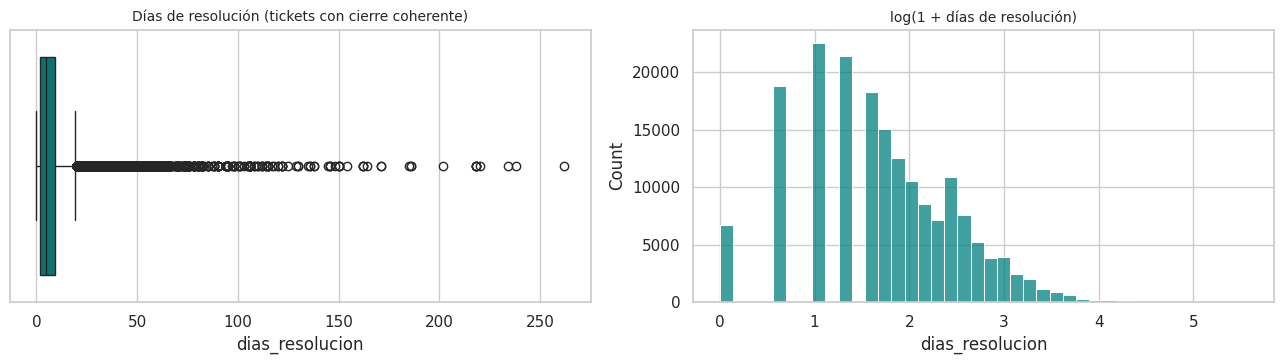

In [17]:
print('=== VALORES ATÍPICOS EN LA VARIABLE DE REGRESIÓN ===')
display(df[['dias_resolucion']].apply(contar_atipicos).T)
print(f"Percentiles 95, 99 y 99,9: {df['dias_resolucion'].quantile([0.95, 0.99, 0.999]).round(1).tolist()}")

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(x=df['dias_resolucion'], ax=ejes[0], color='teal')
ejes[0].set_title('Días de resolución (tickets con cierre coherente)', fontsize=10)
sns.histplot(np.log1p(df['dias_resolucion']), bins=40, ax=ejes[1], color='teal')
ejes[1].set_title('log(1 + días de resolución)', fontsize=10)
plt.tight_layout()
plt.show()

La regla IQR marca el 5,0 % de los tickets por encima de 19,5 días y el Z-score el 1,6 %. El percentil 99 es 34 días y el 99,9 llega a 74. Estos valores no son errores de registro: son incidentes reales que se extendieron, por ejemplo por espera de repuestos. Eliminarlos haría que el modelo subestimara los casos difíciles. Sin embargo, al ser pocos y muy extremos, dominarían el entrenamiento de un modelo que minimiza errores cuadráticos.

**Decisión:** aplicamos **winsorización** del objetivo en el percentil 99, con el límite calculado **solo con el conjunto de entrenamiento** (sección 7.2). Así se conservan todos los tickets, se limita la influencia de los extremos y se evita que la distribución de validación o de prueba influya en el preprocesamiento. La transformación logarítmica, que vuelve la distribución casi simétrica, se descartó porque hace que el modelo prediga la mediana en escala original y subestime sistemáticamente la media de días.

## 5.3 **Auditoría de Fuga de Datos**

Cada modelo debe usar solo información que esté disponible en el momento en que se tomaría la decisión: la apertura del ticket o el despacho del técnico. La siguiente tabla documenta esa revisión para cada grupo de variables.

In [18]:
auditoria = pd.DataFrame([
    ('TIPO_PROBLEMA', 'Sí, se registra en la llamada', 'Objetivo (tipo de falla) / entrada (repuesto y tiempo)'),
    ('NOMBRE_EQUIPO, TECNOLOGIA, CIUDAD, CENTRO_Y_AL', 'Sí, datos del terminal y del comercio', 'Entrada'),
    ('Tecnico', 'Sí, al despachar la visita', 'Entrada solo en regresión (está ligado a la ciudad)'),
    ('Mes, día, temporada, historial del comercio', 'Sí, se calculan con información pasada', 'Entrada'),
    ('ESTADO_ACT', 'Sí, pero es otra escritura de TIPO_PROBLEMA', 'Excluida (fuga directa)'),
    ('Material_Servi_1 a 4, num_repuestos', 'No, se registran al cerrar la visita', 'Solo para construir objetivos'),
    ('FINALIZADO, Estado, dias_resolucion', 'No, ocurren después', 'Solo para construir objetivos'),
], columns=['Variable', '¿Se conoce al abrir el ticket?', 'Uso en el modelado'])
print('=== AUDITORÍA DE FUGA DE DATOS ===')
display(auditoria)

=== AUDITORÍA DE FUGA DE DATOS ===


,Variable,¿Se conoce al abrir el ticket?,Uso en el modelado
0,TIPO_PROBLEMA,"Sí, se registra en la llamada",Objetivo (tipo de falla) / entrada (repuesto y...
1,"NOMBRE_EQUIPO, TECNOLOGIA, CIUDAD, CENTRO_Y_AL","Sí, datos del terminal y del comercio",Entrada
2,Tecnico,"Sí, al despachar la visita",Entrada solo en regresión (está ligado a la ci...
3,"Mes, día, temporada, historial del comercio","Sí, se calculan con información pasada",Entrada
4,ESTADO_ACT,"Sí, pero es otra escritura de TIPO_PROBLEMA",Excluida (fuga directa)
5,"Material_Servi_1 a 4, num_repuestos","No, se registran al cerrar la visita",Solo para construir objetivos
6,"FINALIZADO, Estado, dias_resolucion","No, ocurren después",Solo para construir objetivos


La regla central es que nada que ocurra durante o después de la visita entra como predictor. Los repuestos, la fecha de cierre y el estado final se usan únicamente para construir las variables objetivo. TIPO_PROBLEMA sí puede ser entrada en la regresión y en la predicción de repuestos, porque lo reporta el comercio en la llamada que abre el ticket. Tecnico se usa solo en la regresión: el técnico se conoce al despachar la visita y su ritmo de trabajo influye en el tiempo de cierre.

# 6. Estrategia de Partición de Datos e Imbalance

## 6.1 **Partición Estratificada en Entrenamiento, Validación y Prueba**

Dividimos los tickets en **70 % entrenamiento, 15 % validación y 15 % prueba**, estratificando por TIPO_PROBLEMA, la variable con más clases, para que cada conjunto conserve su distribución. La misma partición se usa en todas las tareas a nivel de ticket. Así, ningún ticket de prueba participa en el entrenamiento de ningún modelo. La validación se usa para comparar modelos y la prueba se reserva para la evaluación final de la sección 12.

In [19]:
from sklearn.model_selection import train_test_split

VARIABLES_CATEGORICAS = ['NOMBRE_EQUIPO', 'TECNOLOGIA', 'CIUDAD', 'CENTRO_Y_AL']
VARIABLES_NUMERICAS = ['es_android', 'es_inalambrico', 'mes_sin', 'mes_cos', 'dia_semana',
                       'es_fin_de_semana', 'temporada_alta', 'tickets_previos_comercio',
                       'dias_desde_ultimo_ticket']

indices = np.arange(len(df))
idx_train, idx_temp = train_test_split(indices, test_size=0.30, stratify=df['TIPO_PROBLEMA'],
                                       random_state=SEMILLA)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=df['TIPO_PROBLEMA'].iloc[idx_temp],
                                     random_state=SEMILLA)
train, val, test = df.iloc[idx_train], df.iloc[idx_val], df.iloc[idx_test]

print('=== PARTICIÓN ESTRATIFICADA 70 / 15 / 15 ===')
for nombre, conjunto in [('Entrenamiento', train), ('Validación', val), ('Prueba', test)]:
    print(f"{nombre:<14} {len(conjunto):>8,} tickets ({len(conjunto) / len(df):.1%}) | "
          f"con cierre válido: {conjunto['dias_resolucion'].notna().sum():>7,} | "
          f"requiere repuesto: {conjunto['requiere_repuesto'].mean():.1%}")

=== PARTICIÓN ESTRATIFICADA 70 / 15 / 15 ===
Entrenamiento   146,412 tickets (70.0%) | con cierre válido: 126,806 | requiere repuesto: 53.4%
Validación       31,374 tickets (15.0%) | con cierre válido:  27,096 | requiere repuesto: 53.3%
Prueba           31,374 tickets (15.0%) | con cierre válido:  27,125 | requiere repuesto: 53.5%


Los tres conjuntos tienen el tamaño esperado y una proporción de visitas con repuesto prácticamente idéntica (53,3 % – 53,5 %). La regresión usa los tickets con cierre coherente dentro de cada conjunto: 126.806 en entrenamiento y unos 27.100 en validación y en prueba.

## 6.2 **Revisión del Balance de Clases**

In [20]:
print('=== BALANCE DE CLASES DE TIPO_PROBLEMA POR CONJUNTO (%) ===')
balance = pd.DataFrame({
    'Entrenamiento': train['TIPO_PROBLEMA'].value_counts(normalize=True),
    'Validación': val['TIPO_PROBLEMA'].value_counts(normalize=True),
    'Prueba': test['TIPO_PROBLEMA'].value_counts(normalize=True),
}).mul(100).round(2)
display(balance)
conteos = train['TIPO_PROBLEMA'].value_counts()
print(f"Razón de desbalance (clase mayor / clase menor): {conteos.max() / conteos.min():.2f}")
print(f"Balance de requiere_repuesto en entrenamiento: {train['requiere_repuesto'].value_counts(normalize=True).round(3).to_dict()}")

=== BALANCE DE CLASES DE TIPO_PROBLEMA POR CONJUNTO (%) ===


,Entrenamiento,Validación,Prueba
TIPO_PROBLEMA,,,
Sin senal o nivel bajo,18.01,18.01,18.01
Falla del pin,11.05,11.05,11.05
Cable de red,10.40,10.40,10.40
POS no carga,8.92,8.92,8.92
Datafono no enciende,8.11,8.11,8.11
Tamper bloqueo,8.00,8.00,8.01
Mantenimiento preventivo,7.64,7.64,7.64
Dano o bloqueo,7.21,7.21,7.21
Reconfiguracion de IP,6.85,6.85,6.85


Razón de desbalance (clase mayor / clase menor): 4.15
Balance de requiere_repuesto en entrenamiento: {1: 0.534, 0: 0.466}


La estratificación replica las proporciones de cada clase en los tres conjuntos con diferencias menores a 0,01 puntos porcentuales. La razón entre la clase más frecuente y la menos frecuente es 4,15. Es un **desbalance moderado, no severo**, por lo que no generamos ejemplos sintéticos con SMOTE o ADASYN: en clases que ya tienen más de 6.000 ejemplos de entrenamiento, la interpolación agregaría ruido sin aportar información. En su lugar, class_weight='balanced' se incluye como hiperparámetro en la búsqueda del Random Forest (sección 9.3), y la validación cruzada decide si conviene. La variable requiere_repuesto está prácticamente balanceada (53 % / 47 %).

## 6.3 **Codificación y Escalamiento sin Fuga de Datos**

La transformación se encapsula en un ColumnTransformer que se integra a cada Pipeline junto con el modelo:
* **One-Hot Encoding** para las categóricas nominales, porque ninguna tiene orden natural. Con handle_unknown='ignore', una categoría no vista en entrenamiento se codifica como ceros en lugar de producir un error.
* **StandardScaler** para las numéricas, necesario en los modelos sensibles a la escala (regresión logística, ElasticNet y perceptrón multicapa).

Como el preprocesador está dentro del pipeline, se ajusta únicamente con los datos que recibe fit. En la validación cruzada esto significa que se reajusta en cada pliegue con los datos de entrenamiento de ese pliegue.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone


def crear_preprocesador(categoricas, numericas):
    """Codificación one-hot y estandarización; ambos se ajustan solo cuando el pipeline se entrena."""
    return ColumnTransformer([
        ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
        ('numericas', StandardScaler(), numericas),
    ])


ENTRADAS_TIPO = VARIABLES_CATEGORICAS + VARIABLES_NUMERICAS
ENTRADAS_REPUESTO = VARIABLES_CATEGORICAS + ['TIPO_PROBLEMA'] + VARIABLES_NUMERICAS
ENTRADAS_REGRESION = VARIABLES_CATEGORICAS + ['TIPO_PROBLEMA', 'Tecnico'] + VARIABLES_NUMERICAS

pre_tipo = crear_preprocesador(VARIABLES_CATEGORICAS, VARIABLES_NUMERICAS)
pre_repuesto = crear_preprocesador(VARIABLES_CATEGORICAS + ['TIPO_PROBLEMA'], VARIABLES_NUMERICAS)
pre_regresion = crear_preprocesador(VARIABLES_CATEGORICAS + ['TIPO_PROBLEMA', 'Tecnico'], VARIABLES_NUMERICAS)

# demostración: el escalador aprende media y desviación únicamente del entrenamiento
demo = clone(pre_tipo).fit(train[ENTRADAS_TIPO])
escalador = demo.named_transformers_['numericas']
print('=== PREPROCESADORES DEFINIDOS ===')
print(f"Columnas tras la codificación (tipo de falla): {demo.transform(train[ENTRADAS_TIPO].head()).shape[1]}")
print('Media aprendida por el escalador (solo entrenamiento):')
display(pd.Series(escalador.mean_, index=VARIABLES_NUMERICAS).round(3).to_frame('media_train'))

=== PREPROCESADORES DEFINIDOS ===
Columnas tras la codificación (tipo de falla): 45
Media aprendida por el escalador (solo entrenamiento):


,media_train
es_android,0.204
es_inalambrico,0.563
mes_sin,-0.008
mes_cos,-0.078
dia_semana,2.668
es_fin_de_semana,0.201
temporada_alta,0.143
tickets_previos_comercio,407.941
dias_desde_ultimo_ticket,2.794


La codificación genera 45 columnas para el modelo de tipo de falla. Las medias que aprendió el escalador provienen exclusivamente del conjunto de entrenamiento. Por ejemplo, el 20,4 % de los tickets de entrenamiento corresponde a terminales Android y el 14,3 % a temporada alta. Esos mismos parámetros se aplican después, sin recalcularse, a validación y prueba.

# 7. Modelo Base (Baseline)

## 7.1 **Clasificación: Dummy Classifier y Regresión Logística**

El modelo base fija el umbral mínimo que cualquier modelo avanzado debe superar. Para cada objetivo de clasificación entrenamos:
* un **Dummy Classifier**, que predice según la frecuencia de las clases sin mirar las variables, y
* una **Regresión Logística básica**, el primer modelo que aprende de las variables.

Para el tipo de falla reportamos, además de exactitud y F1 macro, la **exactitud top-3**: el porcentaje de tickets cuya falla real está entre las tres más probables según el modelo. Es la métrica que corresponde a la decisión de cargar un kit con los repuestos de las tres fallas más probables.

In [22]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, top_k_accuracy_score, r2_score,
                             mean_absolute_error, mean_squared_error)


def metricas_binarias(y_real, probabilidad, umbral=0.5):
    prediccion = (probabilidad >= umbral).astype(int)
    return {'Accuracy': accuracy_score(y_real, prediccion), 'Precision': precision_score(y_real, prediccion),
            'Recall': recall_score(y_real, prediccion), 'F1': f1_score(y_real, prediccion),
            'AUC-ROC': roc_auc_score(y_real, probabilidad)}


def metricas_multiclase(y_real, probabilidades, clases):
    prediccion = clases[np.argmax(probabilidades, axis=1)]
    return {'Accuracy': accuracy_score(y_real, prediccion),
            'Accuracy balanceada': balanced_accuracy_score(y_real, prediccion),
            'F1 macro': f1_score(y_real, prediccion, average='macro'),
            'Top-3 accuracy': top_k_accuracy_score(y_real, probabilidades, k=3, labels=clases)}


print('=== MODELO BASE: ¿LA VISITA REQUIERE REPUESTO? ===')
base_repuesto = {}
for nombre, modelo in [('Dummy (clase mayoritaria)', DummyClassifier(strategy='prior')),
                       ('Regresión Logística', LogisticRegression(max_iter=1000))]:
    tuberia = Pipeline([('pre', clone(pre_repuesto)), ('modelo', modelo)])
    tuberia.fit(train[ENTRADAS_REPUESTO], train['requiere_repuesto'])
    base_repuesto[nombre] = metricas_binarias(val['requiere_repuesto'],
                                              tuberia.predict_proba(val[ENTRADAS_REPUESTO])[:, 1])
display(pd.DataFrame(base_repuesto).T.round(4))

print('\n=== MODELO BASE: TIPO DE FALLA (12 CLASES) ===')
base_tipo = {}
for nombre, modelo in [('Dummy (clase mayoritaria)', DummyClassifier(strategy='prior')),
                       ('Regresión Logística', LogisticRegression(max_iter=1000))]:
    tuberia = Pipeline([('pre', clone(pre_tipo)), ('modelo', modelo)])
    tuberia.fit(train[ENTRADAS_TIPO], train['TIPO_PROBLEMA'])
    base_tipo[nombre] = metricas_multiclase(val['TIPO_PROBLEMA'], tuberia.predict_proba(val[ENTRADAS_TIPO]),
                                            tuberia.classes_)
display(pd.DataFrame(base_tipo).T.round(4))

=== MODELO BASE: ¿LA VISITA REQUIERE REPUESTO? ===


,Accuracy,Precision,Recall,F1,AUC-ROC
Dummy (clase mayoritaria),0.5335,0.5335,1.0000,0.6958,0.5000
Regresión Logística,0.7888,0.8074,0.7933,0.8003,0.8445



=== MODELO BASE: TIPO DE FALLA (12 CLASES) ===


,Accuracy,Accuracy balanceada,F1 macro,Top-3 accuracy
Dummy (clase mayoritaria),0.1801,0.0833,0.0254,0.3946
Regresión Logística,0.3257,0.2224,0.1702,0.6219


* **Requiere repuesto:** la regresión logística alcanza un AUC-ROC de 0,845 y un F1 de 0,800, muy por encima del Dummy (AUC 0,50). La señal es fuerte desde el modelo más simple, porque el tipo de falla reportado determina en gran parte si habrá repuesto (sección 4.3).
* **Tipo de falla:** la exactitud sube de 18,0 % (Dummy) a 32,6 %, y la top-3 de 39,5 % a 62,2 %. El F1 macro de 0,17 muestra que las clases poco frecuentes casi nunca se predicen como primera opción. Esto confirma que la predicción exacta del tipo de falla no es un objetivo realista y que la top-3 es la métrica adecuada para la operación.

## 7.2 **Regresión: Dummy Regressor y Regresión Lineal Simple**

Para dias_resolucion usamos el **Dummy Regressor** (predice siempre la media de entrenamiento) y una **Regresión Lineal Simple** con un único predictor: si la falla es de hardware. Escogimos este predictor porque es el que más separa los tiempos de resolución entre grupos (sección 5.1). Antes de entrenar se winsoriza el objetivo con el percentil 99 de entrenamiento.

In [23]:
print('=== MODELO BASE: DÍAS DE RESOLUCIÓN ===')
train_reg = train.dropna(subset=['dias_resolucion']).copy()
val_reg = val.dropna(subset=['dias_resolucion']).copy()
test_reg = test.dropna(subset=['dias_resolucion']).copy()

# winsorización del objetivo con el percentil 99 calculado SOLO en entrenamiento
LIMITE_DIAS = train_reg['dias_resolucion'].quantile(0.99)
for conjunto in (train_reg, val_reg, test_reg):
    conjunto['dias_resolucion_w'] = conjunto['dias_resolucion'].clip(upper=LIMITE_DIAS)
print(f"Límite de winsorización (percentil 99 de entrenamiento): {LIMITE_DIAS:.0f} días | "
      f"valores recortados en entrenamiento: {(train_reg['dias_resolucion'] > LIMITE_DIAS).sum():,}")

for conjunto in (train_reg, val_reg, test_reg):
    conjunto['es_hardware'] = (conjunto['grupo_falla'] == 'Hardware').astype(int)


def metricas_regresion(y_real, prediccion):
    return {'R2': r2_score(y_real, prediccion), 'MAE (días)': mean_absolute_error(y_real, prediccion),
            'RMSE (días)': np.sqrt(mean_squared_error(y_real, prediccion))}


base_reg = {}
dummy_reg = DummyRegressor(strategy='mean').fit(train_reg[['es_hardware']], train_reg['dias_resolucion_w'])
base_reg['Dummy (media)'] = metricas_regresion(val_reg['dias_resolucion_w'], dummy_reg.predict(val_reg[['es_hardware']]))
lineal_simple = LinearRegression().fit(train_reg[['es_hardware']], train_reg['dias_resolucion_w'])
base_reg['Regresión Lineal Simple (es_hardware)'] = metricas_regresion(
    val_reg['dias_resolucion_w'], lineal_simple.predict(val_reg[['es_hardware']]))
display(pd.DataFrame(base_reg).T.round(4))
print(f"Pendiente: {lineal_simple.coef_[0]:.2f} días adicionales cuando la falla es de hardware "
      f"| intercepto: {lineal_simple.intercept_:.2f} días")

=== MODELO BASE: DÍAS DE RESOLUCIÓN ===
Límite de winsorización (percentil 99 de entrenamiento): 34 días | valores recortados en entrenamiento: 1,222


,R2,MAE (días),RMSE (días)
Dummy (media),-0.0000,4.5417,6.2782
Regresión Lineal Simple (es_hardware),0.2812,3.6787,5.3228


Pendiente: 7.15 días adicionales cuando la falla es de hardware | intercepto: 4.31 días


El límite de winsorización es 34 días y recorta 1.222 tickets de entrenamiento (menos del 1 %). El Dummy comete un error absoluto medio de 4,54 días. La regresión lineal simple lo reduce a 3,68 días y explica el 28 % de la varianza. La pendiente indica que una falla de hardware tarda en promedio **7,15 días más** que las demás (4,31 frente a 11,46 días). Este modelo de una sola variable ya es un piso exigente para la Fase 3.

---
# PARTE III · FASE 3: MODELADO AVANZADO, CLUSTERING, OPTIMIZACIÓN E INTERPRETABILIDAD

# 8. Modelos de Regresión

## 8.1 **Regresión Multivariable Regularizada y Ensamble con Búsqueda de Hiperparámetros**

Comparamos dos familias de modelos para predecir los días de resolución:
* **ElasticNet:** regresión lineal con penalización combinada L1 (Lasso, que puede anular coeficientes) y L2 (Ridge, que los encoge). Es interpretable y robusta ante la colinealidad de las variables geográficas. Se ajustan alpha(fuerza de la penalización) y l1_ratio (proporción L1).
* **Gradient Boosting** (implementación por histogramas de scikit-learn): ensamble secuencial de árboles en el que cada árbol corrige los errores del anterior. Captura interacciones no lineales, por ejemplo que el mismo tipo de falla tarde distinto según la ciudad. Se ajustan la tasa de aprendizaje, la profundidad, el tamaño mínimo de hoja y la regularización L2.

Los hiperparámetros se eligen con **validación cruzada de 3 pliegues** minimizando el MAE. Por costo computacional, la búsqueda del ensamble se hace sobre una muestra aleatoria de 40.000 tickets de entrenamiento; el modelo final se reentrena con todo el entrenamiento usando los mejores parámetros. Comparamos las métricas de entrenamiento y validación para detectar sobreajuste.

In [24]:
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold

print('=== REGRESIÓN AVANZADA: BÚSQUEDA DE HIPERPARÁMETROS CON VALIDACIÓN CRUZADA ===')
X_tr_reg, y_tr_reg = train_reg[ENTRADAS_REGRESION], train_reg['dias_resolucion_w']
X_va_reg, y_va_reg = val_reg[ENTRADAS_REGRESION], val_reg['dias_resolucion_w']
cv_reg = KFold(n_splits=3, shuffle=True, random_state=SEMILLA)

inicio = time.time()
busqueda_enet = GridSearchCV(
    Pipeline([('pre', clone(pre_regresion)), ('modelo', ElasticNet(max_iter=5000))]),
    {'modelo__alpha': [0.001, 0.01, 0.1], 'modelo__l1_ratio': [0.1, 0.5, 0.9]},
    cv=cv_reg, scoring='neg_mean_absolute_error', n_jobs=-1)
busqueda_enet.fit(X_tr_reg, y_tr_reg)
print(f"ElasticNet | mejores parámetros: {busqueda_enet.best_params_} | "
      f"MAE CV: {-busqueda_enet.best_score_:.3f} días | {time.time() - inicio:.0f} s")

# la búsqueda del ensamble se hace sobre una muestra de 40.000 tickets por costo computacional;
# el modelo final se reentrena con todo el entrenamiento usando los mejores parámetros
muestra = X_tr_reg.sample(40_000, random_state=SEMILLA).index
inicio = time.time()
busqueda_gb = GridSearchCV(
    Pipeline([('pre', clone(pre_regresion)), ('modelo', HistGradientBoostingRegressor(random_state=SEMILLA))]),
    {'modelo__learning_rate': [0.05, 0.1], 'modelo__max_depth': [4, 8],
     'modelo__min_samples_leaf': [20, 100], 'modelo__l2_regularization': [0.0, 1.0]},
    cv=cv_reg, scoring='neg_mean_absolute_error', n_jobs=-1)
busqueda_gb.fit(X_tr_reg.loc[muestra], y_tr_reg.loc[muestra])
print(f"Gradient Boosting | mejores parámetros: {busqueda_gb.best_params_} | "
      f"MAE CV: {-busqueda_gb.best_score_:.3f} días | {time.time() - inicio:.0f} s")

modelo_enet = busqueda_enet.best_estimator_
modelo_gb_reg = clone(busqueda_gb.best_estimator_).fit(X_tr_reg, y_tr_reg)

resultados_reg = {}
for nombre, modelo in [('ElasticNet', modelo_enet), ('Gradient Boosting', modelo_gb_reg)]:
    fila_tr = metricas_regresion(y_tr_reg, modelo.predict(X_tr_reg))
    fila_va = metricas_regresion(y_va_reg, modelo.predict(X_va_reg))
    resultados_reg[nombre] = {'R2 train': fila_tr['R2'], 'R2 val': fila_va['R2'],
                              'MAE train': fila_tr['MAE (días)'], 'MAE val': fila_va['MAE (días)'],
                              'RMSE val': fila_va['RMSE (días)']}
resultados_reg['Dummy (media)'] = {'R2 val': base_reg['Dummy (media)']['R2'],
                                   'MAE val': base_reg['Dummy (media)']['MAE (días)'],
                                   'RMSE val': base_reg['Dummy (media)']['RMSE (días)']}
tabla_reg = pd.DataFrame(resultados_reg).T.round(3)
display(tabla_reg)

=== REGRESIÓN AVANZADA: BÚSQUEDA DE HIPERPARÁMETROS CON VALIDACIÓN CRUZADA ===
ElasticNet | mejores parámetros: {'modelo__alpha': 0.01, 'modelo__l1_ratio': 0.5} | MAE CV: 3.119 días | 112 s
Gradient Boosting | mejores parámetros: {'modelo__l2_regularization': 1.0, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 20} | MAE CV: 3.027 días | 45 s


,R2 train,R2 val,MAE train,MAE val,RMSE val
ElasticNet,0.444,0.445,3.117,3.119,4.679
Gradient Boosting,0.485,0.469,2.968,3.012,4.575
Dummy (media),NaN,-0.000,NaN,4.542,6.278


* **ElasticNet** (α = 0,01, l1_ratio = 0,5) alcanza un R² de 0,445 y un MAE de 3,12 días. Su desempeño es idéntico en entrenamiento y validación: como modelo lineal regularizado, no sobreajusta.
* **Gradient Boosting** (profundidad 8, tasa 0,1, hoja mínima 20, regularización L2 = 1) es el mejor modelo: R² de 0,469 y MAE de **3,01 días** en validación. La brecha con entrenamiento es pequeña (R² 0,485 frente a 0,469; MAE 2,97 frente a 3,01), lo que indica que **no hay sobreajuste relevante**.
* Frente al Dummy (MAE 4,54), el Gradient Boosting reduce el error en un 34 %. Frente a la regresión lineal simple (3,68), en un 18 %. La ganancia del ensamble sobre ElasticNet es moderada (0,1 días): la mayor parte de la señal es aditiva (tipo de falla, ciudad, técnico) y el ensamble aporta las interacciones.
* El R² cercano a 0,47 indica que la mitad de la variabilidad del tiempo de cierre depende de factores que no están en los datos, como la disponibilidad real del repuesto o la agenda del comercio.

## 8.2 **Diagnóstico de Residuos**

El análisis de residuos permite verificar si el modelo tiene sesgos sistemáticos y en qué tipos de ticket se concentra el error.

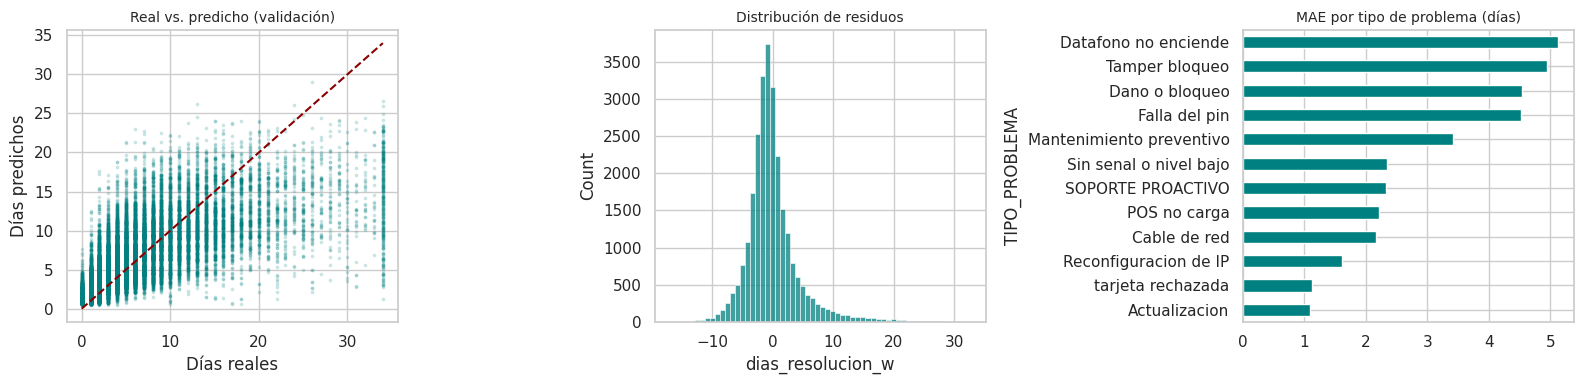

Residuo medio: -0.016 días | mediana del error absoluto: 2.00 días
Tickets de validación con error menor a 3 días: 66.4%


In [25]:
prediccion_val_reg = modelo_gb_reg.predict(X_va_reg)
residuos = y_va_reg - prediccion_val_reg

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
ejes[0].scatter(y_va_reg, prediccion_val_reg, s=3, alpha=0.15, color='teal')
ejes[0].plot([0, LIMITE_DIAS], [0, LIMITE_DIAS], color='darkred', linestyle='--')
ejes[0].set_xlabel('Días reales')
ejes[0].set_ylabel('Días predichos')
ejes[0].set_title('Real vs. predicho (validación)', fontsize=10)
sns.histplot(residuos, bins=60, ax=ejes[1], color='teal')
ejes[1].set_title('Distribución de residuos', fontsize=10)
error_por_tipo = (val_reg.assign(error=np.abs(residuos))
                  .groupby('TIPO_PROBLEMA')['error'].mean().sort_values())
error_por_tipo.plot(kind='barh', ax=ejes[2], color='teal')
ejes[2].set_title('MAE por tipo de problema (días)', fontsize=10)
plt.tight_layout()
plt.show()
print(f"Residuo medio: {residuos.mean():.3f} días | mediana del error absoluto: {np.abs(residuos).median():.2f} días")
print(f"Tickets de validación con error menor a 3 días: {(np.abs(residuos) < 3).mean():.1%}")

* El residuo medio es −0,02 días: el modelo **no tiene sesgo** global. La mediana del error absoluto es 2 días y el 66,4 % de los tickets se predice con un error menor a 3 días.
* El diagrama real versus predicho muestra que el modelo predice bien los tickets cortos, pero **comprime los largos**: casi nunca predice más de 25 días. Es el comportamiento esperado al minimizar el error medio cuando los casos largos son poco frecuentes y dependen de factores no observados.
* El error por tipo de problema confirma esa lectura. Las fallas de hardware (datáfono no enciende, tamper, daño en el teclado, falla del pin) tienen MAE de 4 a 5 días, mientras que actualización y tarjeta rechazada tienen errores cercanos a 1 día. Para la operación, esto sugiere comunicar al comercio un rango y no un valor puntual en las fallas de hardware.

## 8.3 **Pronóstico de Demanda Semanal por Ciudad (Extensión Proactiva)**

Para dimensionar cuántos técnicos se necesitan en cada ciudad pronosticamos el número de tickets de la semana siguiente. Construimos una serie semanal por ciudad y usamos como predictores los rezagos de 1 a 4 semanas, la media móvil de las cuatro semanas previas y un indicador de temporada alta.

A diferencia de las tareas anteriores, aquí la partición es **temporal**: se entrena con las semanas anteriores a marzo de 2026, se valida entre marzo y junio, y se prueba desde julio. Una partición aleatoria permitiría usar semanas futuras para predecir el pasado, una fuga temporal. La referencia es el **pronóstico ingenuo**, que repite la demanda de la semana anterior y es la práctica habitual cuando no hay modelo.

In [26]:
from sklearn.linear_model import Ridge

print('=== PRONÓSTICO DE DEMANDA SEMANAL POR CIUDAD ===')
semanal = (df.groupby([pd.Grouper(key='CREADO_EN_dt', freq='W-SUN'), 'CIUDAD'])
             .size().rename('tickets').reset_index().rename(columns={'CREADO_EN_dt': 'semana'}))
ultima_fecha = df['CREADO_EN_dt'].max()
semanal = semanal[semanal['semana'] <= ultima_fecha]          # se descarta la última semana incompleta
semanal = semanal.sort_values(['CIUDAD', 'semana']).reset_index(drop=True)

grupo_ciudad = semanal.groupby('CIUDAD')['tickets']
for rezago in (1, 2, 3, 4):
    semanal[f'rezago_{rezago}'] = grupo_ciudad.shift(rezago)
semanal['media_movil_4'] = grupo_ciudad.transform(lambda s: s.shift(1).rolling(4).mean())
semanal['mes'] = semanal['semana'].dt.month
semanal['temporada_alta'] = semanal['mes'].isin([12, 1]).astype(int)
semanal = semanal.dropna().reset_index(drop=True)

ENTRADAS_DEMANDA = ['rezago_1', 'rezago_2', 'rezago_3', 'rezago_4', 'media_movil_4', 'temporada_alta']
X_dem = pd.get_dummies(semanal[ENTRADAS_DEMANDA + ['CIUDAD']], columns=['CIUDAD'], dtype=float)

# partición temporal: el modelo nunca ve semanas posteriores a las que pronostica
corte_val, corte_test = pd.Timestamp('2026-03-01'), pd.Timestamp('2026-07-01')
es_tr = semanal['semana'] < corte_val
es_va = (semanal['semana'] >= corte_val) & (semanal['semana'] < corte_test)
es_te = semanal['semana'] >= corte_test
print(f"Semanas-ciudad: entrenamiento {es_tr.sum()}, validación {es_va.sum()}, prueba {es_te.sum()} "
      f"(prueba desde {corte_test.date()})")

modelos_demanda = {
    'Ridge': Pipeline([('escala', StandardScaler()), ('modelo', Ridge(alpha=1.0))]),
    'Gradient Boosting': HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                                       min_samples_leaf=10, random_state=SEMILLA),
}
resultados_demanda = {'Ingenuo (semana anterior)':
                      metricas_regresion(semanal.loc[es_va, 'tickets'], semanal.loc[es_va, 'rezago_1'])}
for nombre, modelo in modelos_demanda.items():
    modelo.fit(X_dem[es_tr], semanal.loc[es_tr, 'tickets'])
    resultados_demanda[nombre] = metricas_regresion(semanal.loc[es_va, 'tickets'], modelo.predict(X_dem[es_va]))
tabla_demanda = pd.DataFrame(resultados_demanda).T.round(3)
tabla_demanda.columns = ['R2 val', 'MAE val (tickets/semana)', 'RMSE val']
display(tabla_demanda)
print(f"Demanda semanal promedio por ciudad en validación: {semanal.loc[es_va, 'tickets'].mean():.0f} tickets")

=== PRONÓSTICO DE DEMANDA SEMANAL POR CIUDAD ===
Semanas-ciudad: entrenamiento 336, validación 108, prueba 102 (prueba desde 2026-07-01)


,R2 val,MAE val (tickets/semana),RMSE val
Ingenuo (semana anterior),0.975,23.444,29.648
Ridge,0.983,19.512,24.774
Gradient Boosting,0.975,21.960,30.031


Demanda semanal promedio por ciudad en validación: 370 tickets


* El pronóstico ingenuo ya explica el 97,5 % de la varianza (R² = 0,975), porque la mayor parte de la variación entre observaciones proviene de las diferencias de tamaño entre ciudades. Por eso la comparación relevante es el **MAE**.
* La **regresión Ridge** reduce el error de 23,4 a **19,5 tickets por semana** (−17 %) en validación. Con una demanda promedio de 370 tickets semanales por ciudad, eso equivale a un error relativo cercano al 5 %. El Gradient Boosting (22,0) apenas supera al pronóstico ingenuo: con solo 336 semanas-ciudad de entrenamiento, el modelo lineal generaliza mejor que el ensamble.
* La ventaja de Ridge proviene de promediar varias semanas (rezagos y media móvil), lo que filtra el ruido semanal que el pronóstico ingenuo copia tal cual.

# 9. Modelos de Clasificación

## 9.1 **Requiere Repuesto: Árbol de Decisión y Random Forest**

Comparamos dos algoritmos de la guía para anticipar si la visita requiere repuesto:
* **Árbol de Decisión:** reglas jerárquicas fáciles de explicar al equipo de operaciones. Se ajustan la profundidad máxima y el tamaño mínimo de hoja, que controlan el sobreajuste.
* **Random Forest:** promedio de muchos árboles entrenados con muestras y variables aleatorias, lo que reduce la varianza del árbol individual. Se ajustan la profundidad, el tamaño de hoja y la proporción de variables en cada división.

La búsqueda usa validación cruzada estratificada de 3 pliegues sobre 40.000 tickets, maximizando el AUC-ROC. El AUC mide la capacidad de ordenar las visitas por probabilidad de necesitar repuesto con independencia del umbral, que se escoge después según el costo operativo (sección 13).

In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

print('=== CLASIFICACIÓN: ¿LA VISITA REQUIERE REPUESTO? ===')
X_tr_rep, y_tr_rep = train[ENTRADAS_REPUESTO], train['requiere_repuesto']
X_va_rep, y_va_rep = val[ENTRADAS_REPUESTO], val['requiere_repuesto']
cv_clf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
muestra_clf = X_tr_rep.sample(40_000, random_state=SEMILLA).index

busquedas = {
    'Árbol de Decisión': GridSearchCV(
        Pipeline([('pre', clone(pre_repuesto)), ('modelo', DecisionTreeClassifier(random_state=SEMILLA))]),
        {'modelo__max_depth': [4, 8, 12, None], 'modelo__min_samples_leaf': [20, 100]},
        cv=cv_clf, scoring='roc_auc', n_jobs=-1),
    'Random Forest': GridSearchCV(
        Pipeline([('pre', clone(pre_repuesto)),
                  ('modelo', RandomForestClassifier(n_estimators=150, random_state=SEMILLA, n_jobs=-1))]),
        {'modelo__max_depth': [10, 20], 'modelo__min_samples_leaf': [5, 25],
         'modelo__max_features': ['sqrt', 0.3]},
        cv=cv_clf, scoring='roc_auc', n_jobs=1),
}
modelos_repuesto, resultados_repuesto = {}, {}
for nombre, busqueda in busquedas.items():
    inicio = time.time()
    busqueda.fit(X_tr_rep.loc[muestra_clf], y_tr_rep.loc[muestra_clf])
    modelo = clone(busqueda.best_estimator_).fit(X_tr_rep, y_tr_rep)
    modelos_repuesto[nombre] = modelo
    m_tr = metricas_binarias(y_tr_rep, modelo.predict_proba(X_tr_rep)[:, 1])
    m_va = metricas_binarias(y_va_rep, modelo.predict_proba(X_va_rep)[:, 1])
    resultados_repuesto[nombre] = {'AUC train': m_tr['AUC-ROC'], **{f'{k} val': v for k, v in m_va.items()}}
    print(f"{nombre}: {busqueda.best_params_} | AUC CV {busqueda.best_score_:.4f} | {time.time() - inicio:.0f} s")

resultados_repuesto['Regresión Logística (base)'] = {f'{k} val': v for k, v in
                                                    base_repuesto['Regresión Logística'].items()}
tabla_repuesto = pd.DataFrame(resultados_repuesto).T.round(4)
display(tabla_repuesto)

=== CLASIFICACIÓN: ¿LA VISITA REQUIERE REPUESTO? ===
Árbol de Decisión: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 100} | AUC CV 0.8398 | 6 s
Random Forest: {'modelo__max_depth': 10, 'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 25} | AUC CV 0.8434 | 136 s


,AUC train,Accuracy val,Precision val,Recall val,F1 val,AUC-ROC val
Árbol de Decisión,0.8473,0.7879,0.8035,0.7975,0.8005,0.8433
Random Forest,0.8512,0.7888,0.8074,0.7933,0.8003,0.8435
Regresión Logística (base),NaN,0.7888,0.8074,0.7933,0.8003,0.8445


* Los dos modelos superan la meta del objetivo específico 1 en validación: el Random Forest obtiene un AUC de 0,844 y un F1 de 0,800, y el Árbol de Decisión 0,843 y 0,801.
* La diferencia entre entrenamiento y validación es menor a 0,01 en AUC (0,851 frente a 0,844 en el Random Forest), por lo que **no hay sobreajuste**. Las restricciones de profundidad y de tamaño de hoja elegidas por la validación cruzada lo controlan.
* Un hallazgo importante es que **ninguno de los modelos de árboles supera a la regresión logística base** (AUC 0,845). Esto indica que la relación es esencialmente aditiva: el tipo de falla reportado define casi toda la probabilidad (sección 10) y no hay interacciones relevantes que los árboles puedan explotar. Desde la parsimonia, la regresión logística sería suficiente. Conservamos el Random Forest como modelo de referencia de la Fase 3 porque cumple el requerimiento de la guía y entrega probabilidades igual de útiles.

## 9.2 **Curvas ROC y Matriz de Confusión**

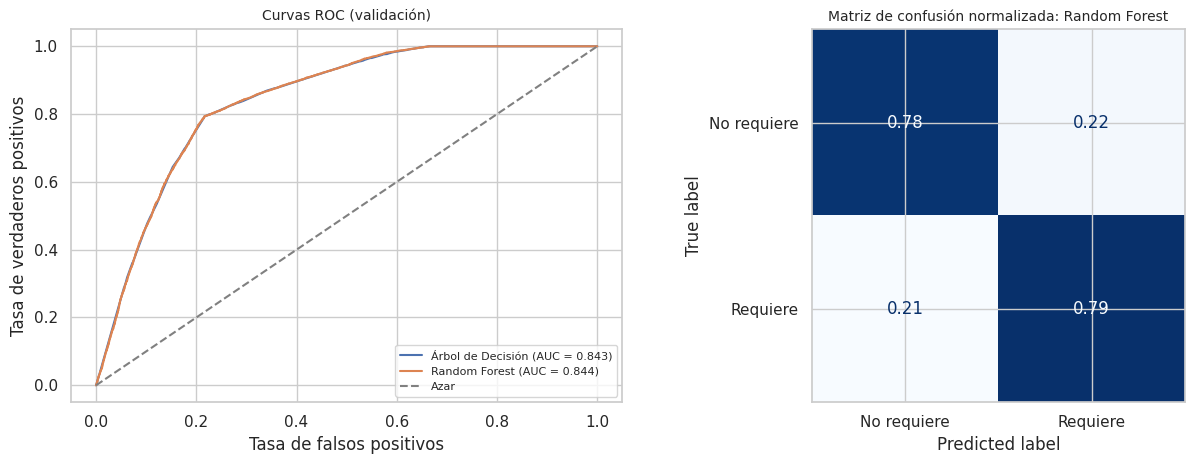

In [28]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

mejor_nombre_rep = tabla_repuesto['AUC-ROC val'].drop('Regresión Logística (base)').idxmax()
mejor_modelo_rep = modelos_repuesto[mejor_nombre_rep]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
for nombre, modelo in modelos_repuesto.items():
    fpr, tpr, _ = roc_curve(y_va_rep, modelo.predict_proba(X_va_rep)[:, 1])
    ejes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {tabla_repuesto.loc[nombre, 'AUC-ROC val']:.3f})")
ejes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Azar')
ejes[0].set_xlabel('Tasa de falsos positivos')
ejes[0].set_ylabel('Tasa de verdaderos positivos')
ejes[0].set_title('Curvas ROC (validación)', fontsize=10)
ejes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_estimator(mejor_modelo_rep, X_va_rep, y_va_rep, normalize='true',
                                      display_labels=['No requiere', 'Requiere'], cmap='Blues',
                                      values_format='.2f', ax=ejes[1], colorbar=False)
ejes[1].set_title(f'Matriz de confusión normalizada: {mejor_nombre_rep}', fontsize=10)
plt.tight_layout()
plt.show()

Las curvas ROC de ambos modelos son prácticamente indistinguibles. Su forma muestra un **codo marcado**: con una tasa de falsos positivos cercana al 22 % se detecta cerca del 80 % de las visitas que requieren repuesto. A partir de ese punto, detectar más casos exige llevar repuestos a muchas visitas que no los necesitan. La matriz de confusión del Random Forest es simétrica: acierta el 78 % de las visitas sin repuesto y el 79 % de las que lo requieren. El modelo no favorece a ninguna de las dos clases.

## 9.3 **Tipo de Falla: Random Forest para el Kit Top-3**

Para el tipo de falla entrenamos un Random Forest cuya búsqueda de hiperparámetros minimiza la **pérdida logarítmica** (log-loss). Elegimos este criterio porque la decisión operativa se basa en el ordenamiento de las probabilidades (las tres fallas más probables) y no solo en la clase más probable. La búsqueda incluye `class_weight='balanced'` como alternativa para el desbalance moderado detectado en la sección 6.2.

In [29]:
print('=== CLASIFICACIÓN: TIPO DE FALLA (12 CLASES) ===')
X_tr_tipo, y_tr_tipo = train[ENTRADAS_TIPO], train['TIPO_PROBLEMA']
X_va_tipo, y_va_tipo = val[ENTRADAS_TIPO], val['TIPO_PROBLEMA']
muestra_tipo = X_tr_tipo.sample(40_000, random_state=SEMILLA).index

inicio = time.time()
busqueda_tipo = GridSearchCV(
    Pipeline([('pre', clone(pre_tipo)),
              ('modelo', RandomForestClassifier(n_estimators=150, random_state=SEMILLA, n_jobs=-1))]),
    {'modelo__max_depth': [8, 14], 'modelo__min_samples_leaf': [50, 200],
     'modelo__class_weight': [None, 'balanced']},
    cv=cv_clf, scoring='neg_log_loss', n_jobs=1)
busqueda_tipo.fit(X_tr_tipo.loc[muestra_tipo], y_tr_tipo.loc[muestra_tipo])
modelo_tipo = clone(busqueda_tipo.best_estimator_).fit(X_tr_tipo, y_tr_tipo)
print(f"Random Forest: {busqueda_tipo.best_params_} | log-loss CV {-busqueda_tipo.best_score_:.4f} | "
      f"{time.time() - inicio:.0f} s")

prob_tipo_val = modelo_tipo.predict_proba(X_va_tipo)
resultados_tipo = dict(base_tipo)
resultados_tipo['Random Forest'] = metricas_multiclase(y_va_tipo, prob_tipo_val, modelo_tipo.classes_)
resultados_tipo['Random Forest']['Accuracy train'] = accuracy_score(y_tr_tipo, modelo_tipo.predict(X_tr_tipo))
display(pd.DataFrame(resultados_tipo).T.round(4))

# cobertura del kit: ¿la falla real está entre las 3 más probables?
top3 = modelo_tipo.classes_[np.argsort(-prob_tipo_val, axis=1)[:, :3]]
acierto_top3 = pd.Series([real in fila for real, fila in zip(y_va_tipo, top3)], index=y_va_tipo.index)
print('\nCobertura top-3 por tipo de falla real (validación):')
display((acierto_top3.groupby(y_va_tipo).mean() * 100).round(1).sort_values(ascending=False).to_frame('% cubierto'))

=== CLASIFICACIÓN: TIPO DE FALLA (12 CLASES) ===
Random Forest: {'modelo__class_weight': None, 'modelo__max_depth': 14, 'modelo__min_samples_leaf': 50} | log-loss CV 2.0107 | 69 s


,Accuracy,Accuracy balanceada,F1 macro,Top-3 accuracy,Accuracy train
Dummy (clase mayoritaria),0.1801,0.0833,0.0254,0.3946,NaN
Regresión Logística,0.3257,0.2224,0.1702,0.6219,NaN
Random Forest,0.3260,0.2216,0.1688,0.6236,0.3315



Cobertura top-3 por tipo de falla real (validación):


,% cubierto
TIPO_PROBLEMA,
Sin senal o nivel bajo,94.0
Cable de red,93.3
POS no carga,76.1
Falla del pin,66.3
Reconfiguracion de IP,65.9
Mantenimiento preventivo,65.1
Tamper bloqueo,58.6
Actualizacion,57.7
Datafono no enciende,28.6


* La validación cruzada eligió **no ponderar las clases** (class_weight=None), una profundidad de 14 y un tamaño mínimo de hoja de 50. Ponderar las clases mejora el F1 macro, pero desordena las probabilidades y reduce la exactitud top-3, que es la métrica operativa.
* El Random Forest alcanza una **exactitud top-3 de 62,4 %**, 23 puntos por encima de la referencia por frecuencias (39,5 %), y supera la meta del objetivo específico 1. En exactitud simple (32,6 %) y top-3 queda al nivel de la regresión logística: como en la sección 9.1, la señal es mayormente aditiva. La brecha entre entrenamiento (33,2 %) y validación (32,6 %) es mínima.
* La cobertura del kit varía mucho según la falla. Las fallas de conectividad (sin señal 94 %, cable de red 93 %, POS no carga 76 %) quedan casi siempre cubiertas, porque dependen de la tecnología del terminal. Las de hardware puro (daño del teclado 22 %, datáfono no enciende 29 %) y tarjeta rechazada (6 %) casi nunca aparecen entre las tres más probables: no dependen del equipo ni de la conectividad, y por eso son las que más conviene confirmar por teléfono antes de despachar.

## 9.4 **Perceptrón Multicapa en PyTorch**

Entrenamos una red neuronal para la misma tarea de repuestos, con el fin de evaluar si un modelo de mayor capacidad encuentra relaciones que los árboles y la regresión logística no capturan:
* **Arquitectura:** entrada (variables codificadas) → 64 neuronas → 32 neuronas → 1 salida, con activación ReLU y *dropout* de 0,2 en las capas ocultas para regularizar.
* **Pérdida:** entropía cruzada binaria sobre *logits* (BCEWithLogitsLoss), numéricamente más estable que aplicar la sigmoide por separado.
* **Optimización:** Adam con tasa de aprendizaje 0,001, decaimiento de pesos 1e-5 y lotes de 1.024 ejemplos.
* **Parada temprana:** el entrenamiento se detiene si la pérdida de validación no mejora en 5 épocas consecutivas, y se restauran los pesos de la mejor época.

El preprocesador se ajusta solo con entrenamiento, igual que en los demás modelos.

=== PERCEPTRÓN MULTICAPA (PYTORCH): ¿LA VISITA REQUIERE REPUESTO? ===
Parada temprana en la época 10
Parámetros entrenables: 5,825


,Accuracy,Precision,Recall,F1,AUC-ROC,AUC train
MLP (PyTorch),0.7883,0.8064,0.7938,0.8,0.8438,0.8466


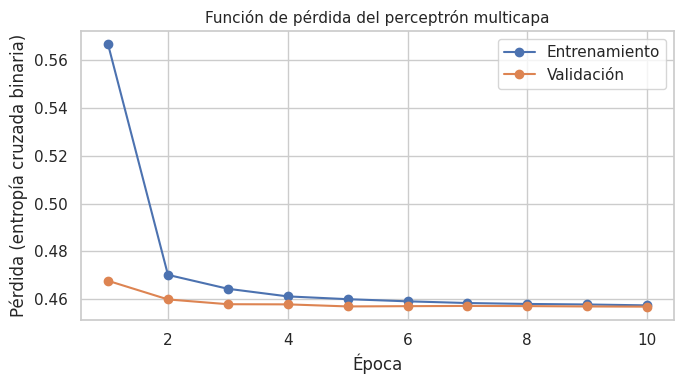

In [30]:
print('=== PERCEPTRÓN MULTICAPA (PYTORCH): ¿LA VISITA REQUIERE REPUESTO? ===')
try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_DISPONIBLE = True
except ImportError:
    TORCH_DISPONIBLE = False
    print('PyTorch no está instalado en este entorno; se omite esta sección.')

if TORCH_DISPONIBLE:
    torch.manual_seed(SEMILLA)
    dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'

    pre_mlp = clone(pre_repuesto).fit(X_tr_rep)            # ajustado solo con entrenamiento
    def a_tensor(X, y):
        return (torch.tensor(pre_mlp.transform(X), dtype=torch.float32),
                torch.tensor(y.values, dtype=torch.float32).unsqueeze(1))
    Xt_tr, yt_tr = a_tensor(X_tr_rep, y_tr_rep)
    Xt_va, yt_va = a_tensor(X_va_rep, y_va_rep)
    cargador = DataLoader(TensorDataset(Xt_tr, yt_tr), batch_size=1024, shuffle=True)

    class PerceptronMulticapa(nn.Module):
        def __init__(self, entradas):
            super().__init__()
            self.red = nn.Sequential(
                nn.Linear(entradas, 64), nn.ReLU(), nn.Dropout(0.2),
                nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
                nn.Linear(32, 1))           # salida en logits; la sigmoide va dentro de la pérdida

        def forward(self, x):
            return self.red(x)

    mlp = PerceptronMulticapa(Xt_tr.shape[1]).to(dispositivo)
    funcion_perdida = nn.BCEWithLogitsLoss()
    optimizador = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-5)

    historial = {'entrenamiento': [], 'validación': []}
    mejor_perdida, paciencia, sin_mejora, mejor_estado = np.inf, 5, 0, None
    for epoca in range(1, 41):
        mlp.train()
        perdida_acumulada = 0.0
        for xb, yb in cargador:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            optimizador.zero_grad()
            perdida = funcion_perdida(mlp(xb), yb)
            perdida.backward()
            optimizador.step()
            perdida_acumulada += perdida.item() * len(xb)
        mlp.eval()
        with torch.no_grad():
            perdida_val = funcion_perdida(mlp(Xt_va.to(dispositivo)), yt_va.to(dispositivo)).item()
        historial['entrenamiento'].append(perdida_acumulada / len(Xt_tr))
        historial['validación'].append(perdida_val)
        if perdida_val < mejor_perdida - 1e-4:
            mejor_perdida, sin_mejora = perdida_val, 0
            mejor_estado = {k: v.detach().clone() for k, v in mlp.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print(f'Parada temprana en la época {epoca}')
                break
    mlp.load_state_dict(mejor_estado)

    def probabilidad_mlp(X):
        mlp.eval()
        with torch.no_grad():
            x = torch.tensor(pre_mlp.transform(X), dtype=torch.float32).to(dispositivo)
            return torch.sigmoid(mlp(x)).cpu().numpy().ravel()

    resultado_mlp_val = metricas_binarias(y_va_rep, probabilidad_mlp(X_va_rep))
    resultado_mlp_val['AUC train'] = roc_auc_score(y_tr_rep, probabilidad_mlp(X_tr_rep))
    print(f'Parámetros entrenables: {sum(p.numel() for p in mlp.parameters()):,}')
    display(pd.DataFrame({'MLP (PyTorch)': resultado_mlp_val}).T.round(4))

    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(historial['entrenamiento']) + 1), historial['entrenamiento'], marker='o', label='Entrenamiento')
    plt.plot(range(1, len(historial['validación']) + 1), historial['validación'], marker='o', label='Validación')
    plt.xlabel('Época')
    plt.ylabel('Pérdida (entropía cruzada binaria)')
    plt.title('Función de pérdida del perceptrón multicapa', fontsize=11)
    plt.legend()
    plt.tight_layout()
    plt.show()

La curva de pérdida es el diagnóstico central de la red. La pérdida de entrenamiento y la de validación descienden juntas durante las primeras épocas y luego se estabilizan. La parada temprana detiene el entrenamiento cuando la validación deja de mejorar, antes de que las curvas se separen, que sería la señal de sobreajuste.

El AUC del perceptrón se ubica en el mismo nivel que el de la regresión logística y los modelos de árboles (alrededor de 0,84). Que tres familias de modelos tan distintas converjan al mismo desempeño indica que se alcanzó el **techo de información** de las variables disponibles al abrir el ticket. Para mejorar la predicción no se necesitan modelos más complejos, sino información adicional, como una descripción textual de la falla o el historial de repuestos del mismo terminal.

# 10. Interpretabilidad de los Modelos

Para explicar qué variables usan los modelos combinamos dos técnicas:
* **Importancia por permutación:** mide cuánto empeora la métrica de validación cuando se desordenan al azar los valores de una variable. Trabaja sobre las variables originales, antes de la codificación, y es independiente del tipo de modelo.
* **Valores SHAP:** descomponen cada predicción individual en la contribución de cada variable codificada. Muestran la dirección del efecto (si una categoría aumenta o reduce la probabilidad), y no solo su magnitud.

=== INTERPRETABILIDAD: IMPORTANCIA POR PERMUTACIÓN (VARIABLES ORIGINALES) ===


,Requiere repuesto (AUC),Días de resolución (MAE),Tipo de falla (accuracy)
TIPO_PROBLEMA,0.3260,1.9380,NaN
TECNOLOGIA,0.0010,0.0089,0.1021
mes_cos,0.0006,0.1568,0.0001
es_inalambrico,0.0006,-0.0006,0.0004
tickets_previos_comercio,0.0004,0.0148,0.0013
mes_sin,0.0003,0.0008,0.0004
dias_desde_ultimo_ticket,0.0002,-0.0027,0.0009
NOMBRE_EQUIPO,0.0002,0.0609,0.0476
dia_semana,0.0001,0.0648,0.0017
es_android,0.0001,0.0006,0.0024


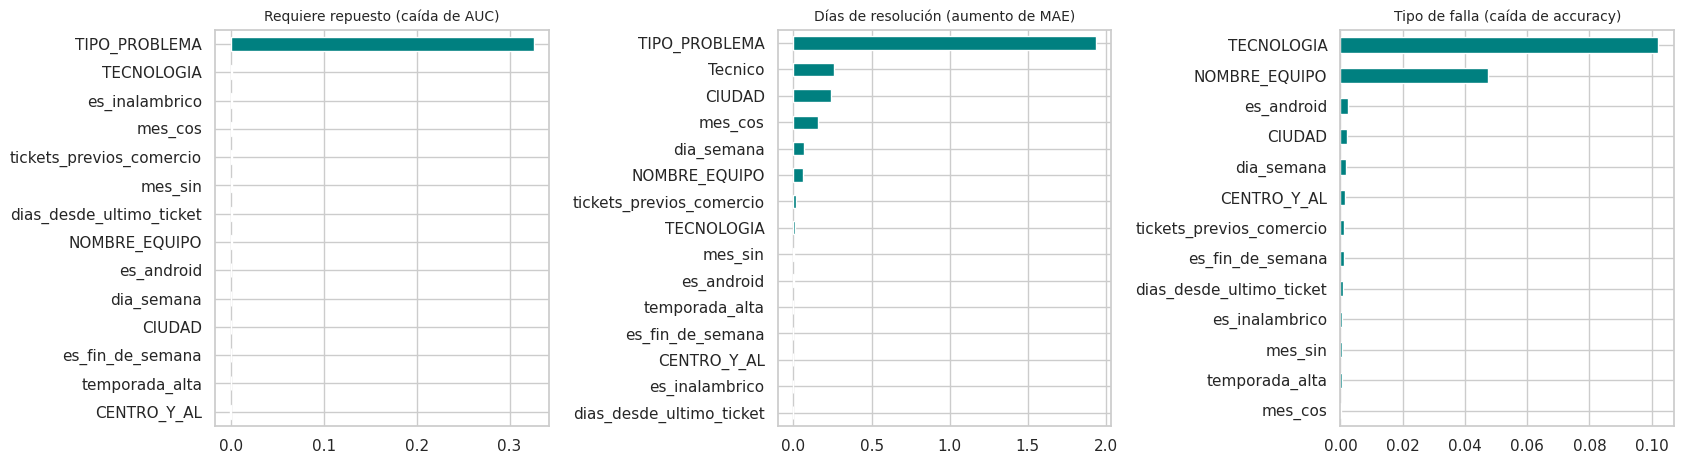

In [31]:
from sklearn.inspection import permutation_importance

print('=== INTERPRETABILIDAD: IMPORTANCIA POR PERMUTACIÓN (VARIABLES ORIGINALES) ===')
muestra_val = val.sample(5_000, random_state=SEMILLA).index


def importancia_permutacion(modelo, X, y, metrica):
    resultado = permutation_importance(modelo, X, y, scoring=metrica, n_repeats=5,
                                       random_state=SEMILLA, n_jobs=1)
    return pd.Series(resultado.importances_mean, index=X.columns).sort_values()


imp_repuesto = importancia_permutacion(mejor_modelo_rep, X_va_rep.loc[muestra_val],
                                       y_va_rep.loc[muestra_val], 'roc_auc')
muestra_val_reg = val_reg.sample(5_000, random_state=SEMILLA).index
imp_regresion = importancia_permutacion(modelo_gb_reg, X_va_reg.loc[muestra_val_reg],
                                        y_va_reg.loc[muestra_val_reg], 'neg_mean_absolute_error')
imp_tipo = importancia_permutacion(modelo_tipo, X_va_tipo.loc[muestra_val],
                                   y_va_tipo.loc[muestra_val], 'accuracy')

tabla_importancia = pd.DataFrame({'Requiere repuesto (AUC)': imp_repuesto,
                                  'Días de resolución (MAE)': imp_regresion,
                                  'Tipo de falla (accuracy)': imp_tipo}).round(4)
display(tabla_importancia.sort_values('Requiere repuesto (AUC)', ascending=False))

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))
for eje, serie, titulo in [(ejes[0], imp_repuesto, 'Requiere repuesto (caída de AUC)'),
                           (ejes[1], imp_regresion, 'Días de resolución (aumento de MAE)'),
                           (ejes[2], imp_tipo, 'Tipo de falla (caída de accuracy)')]:
    serie.plot(kind='barh', ax=eje, color='teal')
    eje.set_title(titulo, fontsize=10)
plt.tight_layout()
plt.show()

* **Requiere repuesto:** TIPO_PROBLEMA es prácticamente la única variable relevante. Desordenarla reduce el AUC en 0,33, mientras que ninguna otra variable lo reduce más de 0,001. El modelo confirma lo observado en la sección 4.3: la falla reportada determina la necesidad de repuesto, y el equipo, la ciudad o el calendario no agregan información.
* **Días de resolución:** TIPO_PROBLEMA es el factor dominante (desordenarlo aumenta el MAE en 1,94 días). Le siguen el técnico (0,26), la ciudad (0,24), el mes (0,16), el día de la semana (0,06) y el modelo de equipo (0,06). Que el técnico y la ciudad pesen indica diferencias de productividad o de carga entre zonas, que se pueden gestionar.
* **Tipo de falla:** la **tecnología del terminal** es la variable más importante (0,10 de caída en exactitud), seguida del modelo de equipo (0,05). Es coherente con la V de Cramér de la sección 3.7.
* Las variables de historial del comercio y de calendario tienen importancia baja en los clasificadores. Esto muestra que, en este dataset, la falla depende del terminal y no de cuándo ocurre ni de cuántas fallas tuvo antes el comercio.

=== INTERPRETABILIDAD: VALORES SHAP DEL MODELO DE REPUESTOS ===


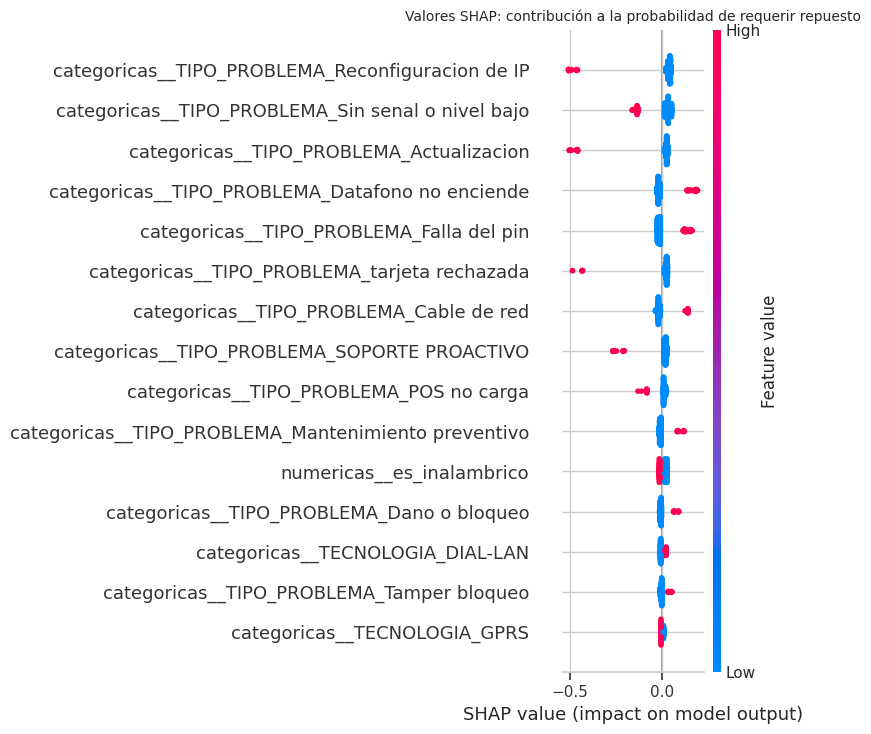

In [32]:
print('=== INTERPRETABILIDAD: VALORES SHAP DEL MODELO DE REPUESTOS ===')
try:
    import shap
    pre_ajustado = mejor_modelo_rep.named_steps['pre']
    arbol = mejor_modelo_rep.named_steps['modelo']
    X_shap = pd.DataFrame(pre_ajustado.transform(X_va_rep.loc[muestra_val[:300]]),
                          columns=pre_ajustado.get_feature_names_out())
    valores = shap.TreeExplainer(arbol).shap_values(X_shap)
    if isinstance(valores, list):
        valores = valores[1]
    elif np.ndim(valores) == 3:
        valores = valores[:, :, 1]
    shap.summary_plot(valores, X_shap, max_display=15, show=False)
    plt.title('Valores SHAP: contribución a la probabilidad de requerir repuesto', fontsize=10)
    plt.tight_layout()
    plt.show()
except ImportError:
    print('La librería shap no está instalada en este entorno; la interpretación se apoya en la importancia por permutación.')
except Exception as error:
    print(f'No fue posible calcular los valores SHAP ({type(error).__name__}); la interpretación se apoya en la importancia por permutación.')

El gráfico SHAP confirma la lectura anterior con el detalle de cada categoría. Las categorías de TIPO_PROBLEMA ocupan los primeros lugares. Las fallas que nunca requieren repuesto (actualización, reconfiguración de IP, tarjeta rechazada) empujan la probabilidad hacia abajo. Las de hardware, como datáfono no enciende, cable de red o falla del pin, la empujan hacia arriba. Las demás variables tienen contribuciones cercanas a cero. Para el equipo de operaciones, esto se traduce en una regla simple y auditable: el kit de repuestos se define principalmente por la falla que reporta el comercio.

# 11. Clustering de Comercios

## 11.1 **Tabla de Indicadores por Comercio**

Para segmentar los comercios agregamos los tickets por USUARIO y construimos ocho indicadores cuantitativos: volumen mensual de tickets, número de equipos, porcentaje de fallas de conectividad, hardware y preventivo, porcentaje de visitas con repuesto, días promedio de resolución y porcentaje de terminales inalámbricos. Antes de agrupar revisamos sus atípicos.

In [33]:
print('=== TABLA DE INDICADORES POR COMERCIO ===')
meses_observados = (df['CREADO_EN_dt'].max() - df['CREADO_EN_dt'].min()).days / 30.44
tabla_comercios = df.groupby('USUARIO').agg(
    tickets_mes=('ID_Llamada', lambda s: len(s) / meses_observados),
    equipos=('Serial_Actuac', 'nunique'),
    pct_conectividad=('grupo_falla', lambda s: (s == 'Conectividad').mean() * 100),
    pct_hardware=('grupo_falla', lambda s: (s == 'Hardware').mean() * 100),
    pct_preventivo=('grupo_falla', lambda s: (s == 'Preventivo').mean() * 100),
    pct_requiere_repuesto=('requiere_repuesto', lambda s: s.mean() * 100),
    dias_resolucion_prom=('dias_resolucion', 'mean'),
    pct_inalambrico=('es_inalambrico', lambda s: s.mean() * 100),
)
tabla_comercios['dias_resolucion_prom'] = tabla_comercios['dias_resolucion_prom'].fillna(
    tabla_comercios['dias_resolucion_prom'].median())
display(tabla_comercios.describe().round(2))
display(tabla_comercios.apply(contar_atipicos).T[['Atípicos IQR', '% IQR', 'Atípicos Z>3', '% Z']])

=== TABLA DE INDICADORES POR COMERCIO ===


,tickets_mes,equipos,pct_conectividad,pct_hardware,pct_preventivo,pct_requiere_repuesto,dias_resolucion_prom,pct_inalambrico
count,900.00,900.00,900.00,900.00,900.00,900.00,900.00,900.00
mean,10.64,3.58,46.62,35.01,6.98,49.35,7.09,69.28
std,16.88,4.16,14.40,14.01,5.75,10.60,2.79,33.80
min,0.37,1.00,4.00,0.00,0.00,7.69,2.14,0.00
25%,3.06,1.00,37.12,25.35,3.41,41.77,5.30,45.89
50%,5.58,2.00,44.51,33.91,5.65,50.86,6.29,77.49
75%,10.09,4.00,53.58,44.19,8.17,56.69,8.09,100.00
max,159.30,20.00,92.09,90.32,26.43,77.78,20.45,100.00


,Atípicos IQR,% IQR,Atípicos Z>3,% Z
tickets_mes,96.0,10.67,23.0,2.56
equipos,91.0,10.11,38.0,4.22
pct_conectividad,36.0,4.00,3.0,0.33
pct_hardware,1.0,0.11,1.0,0.11
pct_preventivo,99.0,11.00,9.0,1.00
pct_requiere_repuesto,6.0,0.67,5.0,0.56
dias_resolucion_prom,61.0,6.78,13.0,1.44
pct_inalambrico,0.0,0.00,0.0,0.00


* Los 900 comercios son muy heterogéneos en volumen: la mediana es de 5,6 tickets por mes, pero el máximo llega a 159. Esta asimetría genera un 10,7 % de atípicos IQR en tickets_mes y un 10,1 % en equipos.
* Los atípicos no son errores: son las grandes cuentas, justamente las de mayor interés para el mantenimiento preventivo. Por eso no los eliminamos. Aplicamos una transformación logarítmica al volumen y al número de equipos, y winsorización en los percentiles 1 y 99 a todos los indicadores, para que unos pocos comercios no definan solos los centroides. Como el clustering no tiene conjunto de prueba, este tratamiento sobre toda la tabla no genera fuga de datos.

## 11.2 **K-Means: Selección del Número Óptimo de Clústeres**

Estandarizamos los indicadores (K-Means usa distancias euclidianas y es sensible a la escala) y evaluamos *k* entre 2 y 8 con dos criterios:
* El **método del codo**, que busca el punto en que agregar clústeres deja de reducir de forma importante la inercia intra-clúster.
* El **coeficiente de silueta**, que compara la cohesión de cada comercio con su grupo frente a su separación del grupo más cercano (de −1 a 1).

=== SELECCIÓN DEL NÚMERO DE CLÚSTERES ===


,Inercia,Silueta
k,,
2,5010.427,0.272
3,3663.375,0.314
4,3146.520,0.247
5,2716.530,0.253
6,2459.292,0.264
7,2266.619,0.245
8,2123.461,0.242


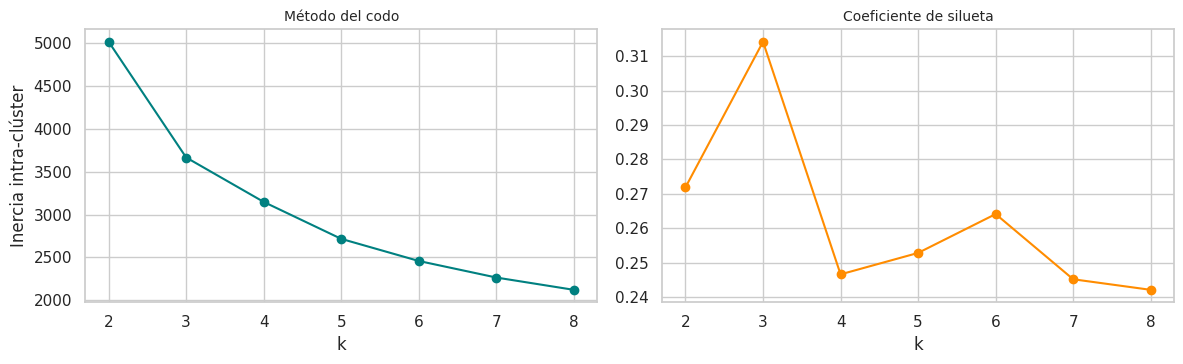

k seleccionado (máxima silueta): 3


In [34]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

# tratamiento de atípicos: log en el volumen (muy asimétrico) y winsorización 1-99 en todas las variables
datos_cluster = tabla_comercios.copy()
datos_cluster['tickets_mes'] = np.log1p(datos_cluster['tickets_mes'])
datos_cluster['equipos'] = np.log1p(datos_cluster['equipos'])
limites = datos_cluster.quantile([0.01, 0.99])
datos_cluster = datos_cluster.clip(limites.loc[0.01], limites.loc[0.99], axis=1)
Z_cluster = StandardScaler().fit_transform(datos_cluster)

print('=== SELECCIÓN DEL NÚMERO DE CLÚSTERES ===')
evaluacion_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Z_cluster)
    evaluacion_k.append({'k': k, 'Inercia': km.inertia_, 'Silueta': silhouette_score(Z_cluster, km.labels_)})
evaluacion_k = pd.DataFrame(evaluacion_k).set_index('k')
display(evaluacion_k.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].plot(evaluacion_k.index, evaluacion_k['Inercia'], marker='o', color='teal')
ejes[0].set_title('Método del codo', fontsize=10)
ejes[0].set_xlabel('k')
ejes[0].set_ylabel('Inercia intra-clúster')
ejes[1].plot(evaluacion_k.index, evaluacion_k['Silueta'], marker='o', color='darkorange')
ejes[1].set_title('Coeficiente de silueta', fontsize=10)
ejes[1].set_xlabel('k')
plt.tight_layout()
plt.show()

K_OPTIMO = int(evaluacion_k['Silueta'].idxmax())
print(f'k seleccionado (máxima silueta): {K_OPTIMO}')

Los dos criterios coinciden en **k = 3**. La silueta alcanza su máximo en ese valor (0,314) y cae a 0,247 con cuatro clústeres. En la curva del codo, la mayor reducción de inercia ocurre al pasar de 2 a 3 grupos (de 5.010 a 3.663) y a partir de 4 la curva se vuelve casi lineal. Una silueta de 0,31 indica una estructura de segmentos real pero con fronteras graduales, lo esperable al agrupar comercios cuyo perfil varía de forma continua.

## 11.3 **Clustering Jerárquico Aglomerativo y Comparación**

Como segundo algoritmo aplicamos **clustering jerárquico aglomerativo con enlace de Ward**, que fusiona en cada paso los dos grupos cuya unión menos aumenta la varianza interna. Lo preferimos sobre DBSCAN porque los indicadores no forman regiones densas separadas por zonas vacías (el espacio PCA muestra una nube continua), una condición que DBSCAN necesita para funcionar bien. El dendrograma permite además verificar visualmente la elección de *k*.

,Silueta,Tamaño de los grupos
K-Means,0.314,"{'Conectividad inalámbrica': 422, 'Grandes cue..."
Jerárquico (Ward),0.256,"{'Conectividad inalámbrica': 359, 'Grandes cue..."


Índice de Rand ajustado entre ambas particiones: 0.508


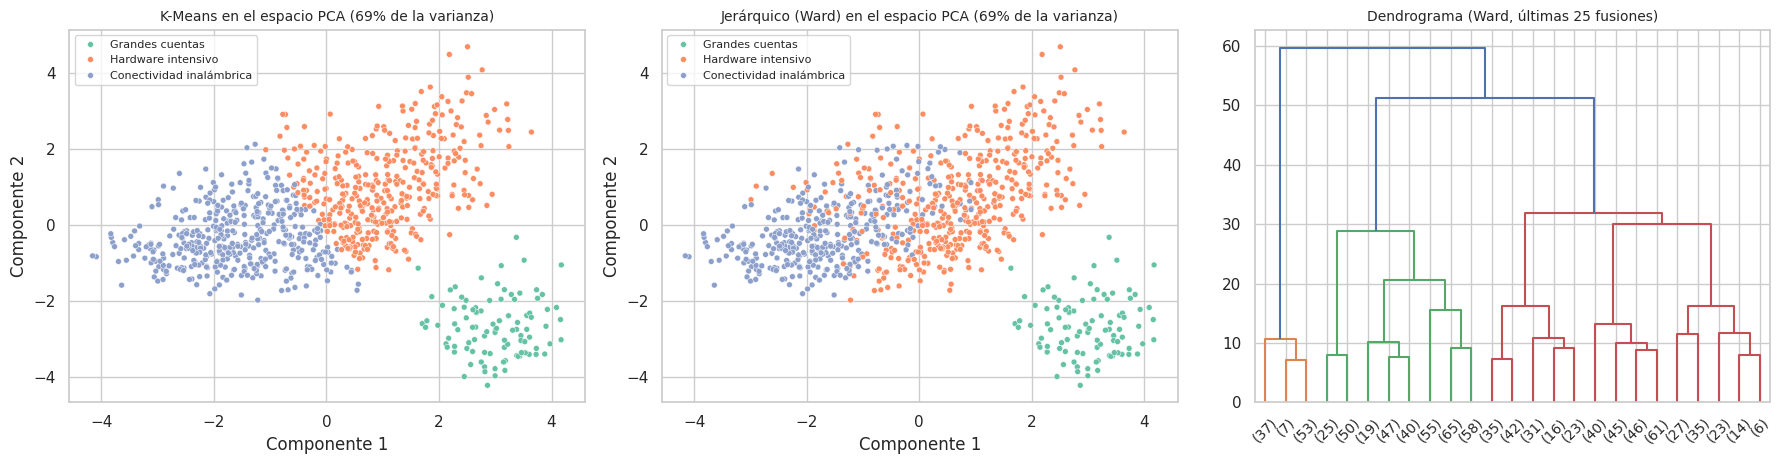

In [35]:
from scipy.cluster.hierarchy import linkage, dendrogram

kmeans = KMeans(n_clusters=K_OPTIMO, n_init=20, random_state=SEMILLA).fit(Z_cluster)
jerarquico = AgglomerativeClustering(n_clusters=K_OPTIMO, linkage='ward').fit(Z_cluster)
INDICADORES = list(tabla_comercios.columns)


def nombrar_segmentos(etiquetas):
    """Asigna nombres según el perfil de cada grupo, para que no dependan de la numeración del algoritmo."""
    perfil = tabla_comercios[INDICADORES].groupby(etiquetas).mean()
    if len(perfil) != 3:
        return pd.Series(etiquetas, index=tabla_comercios.index).map(lambda e: f'Segmento {e}')
    grandes = perfil['tickets_mes'].idxmax()
    hardware = perfil.drop(index=grandes)['pct_hardware'].idxmax()
    nombres = {grandes: 'Grandes cuentas', hardware: 'Hardware intensivo'}
    for etiqueta in perfil.index:
        nombres.setdefault(etiqueta, 'Conectividad inalámbrica')
    return pd.Series(etiquetas, index=tabla_comercios.index).map(nombres)


tabla_comercios['segmento_kmeans'] = nombrar_segmentos(kmeans.labels_)
tabla_comercios['segmento_jerarquico'] = nombrar_segmentos(jerarquico.labels_)

comparacion_cluster = pd.DataFrame({
    'Silueta': [silhouette_score(Z_cluster, kmeans.labels_), silhouette_score(Z_cluster, jerarquico.labels_)],
    'Tamaño de los grupos': [tabla_comercios['segmento_kmeans'].value_counts().sort_index().to_dict(),
                             tabla_comercios['segmento_jerarquico'].value_counts().sort_index().to_dict()],
}, index=['K-Means', 'Jerárquico (Ward)'])
display(comparacion_cluster.round(3))
print(f"Índice de Rand ajustado entre ambas particiones: "
      f"{adjusted_rand_score(kmeans.labels_, jerarquico.labels_):.3f}")

pca = PCA(n_components=2, random_state=SEMILLA).fit(Z_cluster)
coordenadas = pca.transform(Z_cluster)
fig, ejes = plt.subplots(1, 3, figsize=(18, 4.8))
orden_segmentos = ['Grandes cuentas', 'Hardware intensivo', 'Conectividad inalámbrica']
for eje, columna, titulo in [(ejes[0], 'segmento_kmeans', 'K-Means'),
                             (ejes[1], 'segmento_jerarquico', 'Jerárquico (Ward)')]:
    sns.scatterplot(x=coordenadas[:, 0], y=coordenadas[:, 1], hue=tabla_comercios[columna].values,
                    hue_order=[s for s in orden_segmentos if s in set(tabla_comercios[columna])],
                    palette='Set2', s=18, ax=eje)
    eje.legend(fontsize=8)
    eje.set_title(f'{titulo} en el espacio PCA ({pca.explained_variance_ratio_.sum():.0%} de la varianza)',
                  fontsize=10)
    eje.set_xlabel('Componente 1')
    eje.set_ylabel('Componente 2')
dendrogram(linkage(Z_cluster, method='ward'), truncate_mode='lastp', p=25, ax=ejes[2], color_threshold=None)
ejes[2].set_title('Dendrograma (Ward, últimas 25 fusiones)', fontsize=10)
plt.tight_layout()
plt.show()

* **K-Means** obtiene una silueta mayor (0,314 frente a 0,256) y, por lo tanto, una partición más compacta. Es el modelo que adoptamos.
* El índice de Rand ajustado entre las dos particiones es 0,51: coinciden de forma sustancial, aunque no total. **Ambos algoritmos aíslan el mismo grupo de 97 comercios**; la diferencia está en la frontera entre los otros dos segmentos, que el espacio PCA muestra como contiguos.
* El dendrograma presenta tres ramas principales separadas por saltos grandes de distancia, lo que respalda de forma independiente la elección de k = 3. Las dos primeras componentes principales conservan el 69 % de la varianza, suficiente para que la visualización sea representativa.

## 11.4 **Perfiles de los Segmentos y Estrategias de Mantenimiento**

Interpretamos cada segmento a partir de sus indicadores promedio, en unidades originales y en desviaciones estándar respecto al promedio de comercios. Los nombres de los segmentos se asignan en el código según su perfil (el de mayor volumen y, entre los otros dos, el de mayor proporción de hardware), de modo que no dependen de la numeración interna del algoritmo.

=== PERFIL PROMEDIO DE CADA SEGMENTO (K-MEANS) ===


,comercios,tickets_mes,equipos,pct_conectividad,pct_hardware,pct_preventivo,pct_requiere_repuesto,dias_resolucion_prom,pct_inalambrico,% de los tickets
segmento_kmeans,,,,,,,,,,
Conectividad inalámbrica,422,5.17,1.84,55.83,24.79,4.88,41.16,6.38,93.63,22.78
Grandes cuentas,97,45.58,14.39,40.96,31.18,21.07,57.01,6.33,41.24,46.18
Hardware intensivo,381,7.80,2.76,37.87,47.30,5.71,56.46,8.06,49.45,31.04


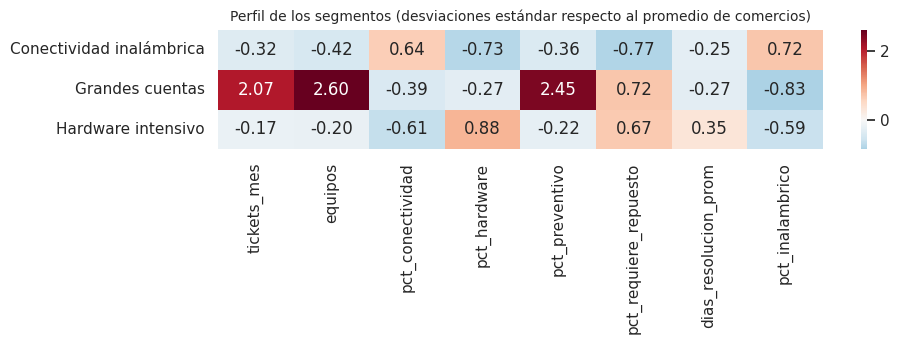

In [36]:
print('=== PERFIL PROMEDIO DE CADA SEGMENTO (K-MEANS) ===')
perfiles = tabla_comercios.groupby('segmento_kmeans').agg(
    comercios=('tickets_mes', 'size'),
    **{columna: (columna, 'mean') for columna in INDICADORES})
perfiles['% de los tickets'] = (tabla_comercios.groupby('segmento_kmeans')['tickets_mes'].sum()
                                / tabla_comercios['tickets_mes'].sum() * 100)
display(perfiles.round(2))

fig, eje = plt.subplots(figsize=(10, 3.6))
estandarizado = (perfiles[INDICADORES] - tabla_comercios[INDICADORES].mean()) / tabla_comercios[INDICADORES].std()
sns.heatmap(estandarizado, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=eje)
eje.set_title('Perfil de los segmentos (desviaciones estándar respecto al promedio de comercios)', fontsize=10)
eje.set_ylabel('')
plt.tight_layout()
plt.show()

| Segmento | Perfil | Estrategia preventiva propuesta |
| :--- | :--- | :--- |
| **Hardware intensivo** (381 comercios, 31 % de los tickets) | 47 % de fallas de hardware (+0,9 DE), 56 % de visitas con repuesto y el mayor tiempo de resolución (8,1 días) | Revisión física programada del terminal (teclado, pin pad, batería), stock local de repuestos de hardware y reemplazo anticipado de equipos con fallas repetidas |
| **Conectividad inalámbrica** (422 comercios, 23 % de los tickets) | 94 % de terminales inalámbricos, 56 % de fallas de conectividad y solo 41 % de visitas con repuesto | Soporte remoto de primer nivel (reconfiguración, diagnóstico de señal) antes de despachar, y evaluación de migrar a operador o tecnología con mejor cobertura |
| **Grandes cuentas** (97 comercios, 46 % de los tickets) | 46 tickets al mes y 14 equipos en promedio (+2 DE), con la mayor proporción de mantenimiento preventivo (21 %) | Técnico o visita programada dedicada, acuerdos de nivel de servicio específicos y mantenimiento preventivo calendarizado, porque concentran casi la mitad de la demanda en el 11 % de los comercios |

El segmento de grandes cuentas es el de mayor impacto: atender de forma preventiva a 97 comercios incide sobre casi la mitad de los tickets de la operación.

# 12. Evaluación Final sobre el Conjunto de Prueba

Evaluamos una sola vez, sobre el conjunto de prueba reservado desde la sección 6, los modelos elegidos en validación. El pronóstico de demanda se reentrena con entrenamiento y validación antes de pronosticar el periodo de prueba (julio a octubre de 2026). La tabla compara cada resultado con la meta definida en los objetivos SMART.

In [37]:
print('=== EVALUACIÓN FINAL SOBRE EL CONJUNTO DE PRUEBA (DATOS NUNCA VISTOS) ===')
X_te_rep, y_te_rep = test[ENTRADAS_REPUESTO], test['requiere_repuesto']
prob_rep_test = mejor_modelo_rep.predict_proba(X_te_rep)[:, 1]
final_rep = metricas_binarias(y_te_rep, prob_rep_test)

prob_tipo_test = modelo_tipo.predict_proba(test[ENTRADAS_TIPO])
final_tipo = metricas_multiclase(test['TIPO_PROBLEMA'], prob_tipo_test, modelo_tipo.classes_)
prior_tipo = train['TIPO_PROBLEMA'].value_counts(normalize=True).reindex(modelo_tipo.classes_).values
top3_referencia = top_k_accuracy_score(test['TIPO_PROBLEMA'], np.tile(prior_tipo, (len(test), 1)),
                                       k=3, labels=modelo_tipo.classes_)

X_te_reg, y_te_reg = test_reg[ENTRADAS_REGRESION], test_reg['dias_resolucion_w']
final_reg = metricas_regresion(y_te_reg, modelo_gb_reg.predict(X_te_reg))
final_reg_dummy = metricas_regresion(y_te_reg, np.full(len(y_te_reg), y_tr_reg.mean()))

nombre_mejor_demanda = tabla_demanda.drop('Ingenuo (semana anterior)')['MAE val (tickets/semana)'].idxmin()
mejor_demanda = modelos_demanda[nombre_mejor_demanda]
es_trva = es_tr | es_va
mejor_demanda.fit(X_dem[es_trva], semanal.loc[es_trva, 'tickets'])     # se reentrena con train + val
pred_demanda_test = mejor_demanda.predict(X_dem[es_te])
final_dem = metricas_regresion(semanal.loc[es_te, 'tickets'], pred_demanda_test)
final_dem_ingenuo = metricas_regresion(semanal.loc[es_te, 'tickets'], semanal.loc[es_te, 'rezago_1'])

filas_finales = [
    ('Requiere repuesto', mejor_nombre_rep, 'AUC-ROC', final_rep['AUC-ROC'], 0.80),
    ('Requiere repuesto', mejor_nombre_rep, 'F1', final_rep['F1'], 0.75),
    ('Tipo de falla', 'Random Forest', 'Top-3 accuracy', final_tipo['Top-3 accuracy'], top3_referencia + 0.15),
    ('Tipo de falla', 'Random Forest', 'F1 macro', final_tipo['F1 macro'], None),
    ('Días de resolución', 'Gradient Boosting', 'MAE (días)', final_reg['MAE (días)'], 0.85 * final_reg_dummy['MAE (días)']),
    ('Días de resolución', 'Gradient Boosting', 'R2', final_reg['R2'], None),
    ('Demanda semanal por ciudad', nombre_mejor_demanda, 'MAE (tickets)', final_dem['MAE (días)'],
     final_dem_ingenuo['MAE (días)']),
    ('Segmentación de comercios', 'K-Means', 'Silueta', silhouette_score(Z_cluster, kmeans.labels_), 0.25),
]
if TORCH_DISPONIBLE:
    filas_finales.insert(2, ('Requiere repuesto', 'MLP (PyTorch)', 'AUC-ROC',
                             roc_auc_score(y_te_rep, probabilidad_mlp(X_te_rep)), 0.80))
resumen_final = pd.DataFrame(filas_finales, columns=['Tarea', 'Modelo', 'Métrica', 'Valor en prueba', 'Meta'])
def cumple(fila):
    if pd.isna(fila['Meta']):
        return '—'
    logrado = fila['Valor en prueba'] <= fila['Meta'] if fila['Métrica'].startswith('MAE') \
        else fila['Valor en prueba'] >= fila['Meta']
    return 'Sí' if logrado else 'No'


resumen_final['¿Cumple?'] = resumen_final.apply(cumple, axis=1)
display(resumen_final.round(4))
print(f"Referencia top-3 sin modelo (frecuencias de entrenamiento): {top3_referencia:.4f}")
print(f"MAE del Dummy en prueba (regresión): {final_reg_dummy['MAE (días)']:.3f} días | "
      f"MAE del pronóstico ingenuo (demanda): {final_dem_ingenuo['MAE (días)']:.1f} tickets")

=== EVALUACIÓN FINAL SOBRE EL CONJUNTO DE PRUEBA (DATOS NUNCA VISTOS) ===


,Tarea,Modelo,Métrica,Valor en prueba,Meta,¿Cumple?
0,Requiere repuesto,Random Forest,AUC-ROC,0.8419,0.8000,Sí
1,Requiere repuesto,Random Forest,F1,0.7971,0.7500,Sí
2,Requiere repuesto,MLP (PyTorch),AUC-ROC,0.8414,0.8000,Sí
3,Tipo de falla,Random Forest,Top-3 accuracy,0.6238,0.5446,Sí
4,Tipo de falla,Random Forest,F1 macro,0.1690,NaN,—
5,Días de resolución,Gradient Boosting,MAE (días),2.9755,3.8520,Sí
6,Días de resolución,Gradient Boosting,R2,0.4773,NaN,—
7,Demanda semanal por ciudad,Ridge,MAE (tickets),18.7629,21.4314,Sí
8,Segmentación de comercios,K-Means,Silueta,0.3142,0.2500,Sí


Referencia top-3 sin modelo (frecuencias de entrenamiento): 0.3946
MAE del Dummy en prueba (regresión): 4.532 días | MAE del pronóstico ingenuo (demanda): 21.4 tickets


**Todos los objetivos específicos se cumplen en datos no vistos**, y los valores de prueba son consistentes con los de validación, lo que confirma que la selección de modelos no sobreajustó el conjunto de validación:

| Objetivo | Resultado en prueba | Meta |
| :--- | :--- | :--- |
| OE1 · Requiere repuesto | AUC 0,842, F1 0,797 | AUC ≥ 0,80, F1 ≥ 0,75 |
| OE1 · Kit top-3 | Exactitud top-3 62,4 % (referencia 39,5 %) | ≥ 54,5 % |
| OE2 · Días de resolución | MAE 2,98 días, R² 0,48 (Dummy: 4,53) | MAE ≤ 3,85 días |
| OE2 · Demanda semanal | MAE 18,8 tickets (ingenuo: 21,4) | MAE < 21,4 |
| OE3 · Segmentación | Silueta 0,314 | ≥ 0,25 |

Hay que matizar el logro del OE1 en repuestos. La meta de AUC se alcanzaba ya con la regresión logística base, así que el aporte de la Fase 3 en esa tarea es confirmar que no hay señal adicional que explotar, más que aumentar el desempeño. El F1 macro del tipo de falla (0,17) recuerda que la predicción exacta de la falla sigue siendo débil. La propuesta operativa se apoya en la top-3, no en la primera opción.

# 13. Impacto Operativo: Política de Despacho de Repuestos

Un modelo de clasificación entrega probabilidades. La decisión de llevar o no un repuesto depende del **umbral** que se fije, y ese umbral expresa un equilibrio entre dos costos: una visita fallida por no llevar el repuesto (hay que volver) frente a un repuesto transportado sin necesidad (inventario inmovilizado). Simulamos varias políticas sobre el conjunto de prueba y graficamos el pronóstico de demanda en el mismo periodo.

=== TRADUCCIÓN OPERATIVA: POLÍTICA DE DESPACHO DE REPUESTOS ===


,% de visitas despachadas con repuesto,% de visitas con necesidad cubierta (recall),% de repuestos llevados que se usan (precision),Visitas que necesitaban repuesto y no lo llevaban
Umbral de probabilidad,,,,
0.3,80.3,98.3,65.5,292
0.4,61.7,86.2,74.7,2315
0.5,52.4,78.9,80.5,3542
0.7,48.8,74.2,81.3,4336
0.8,24.9,39.4,84.6,10179


Referencia sin modelo: llevar repuesto siempre cubre el 100 % con una tasa de uso de 53.5%; no llevarlo nunca deja sin cubrir 16,786 visitas.


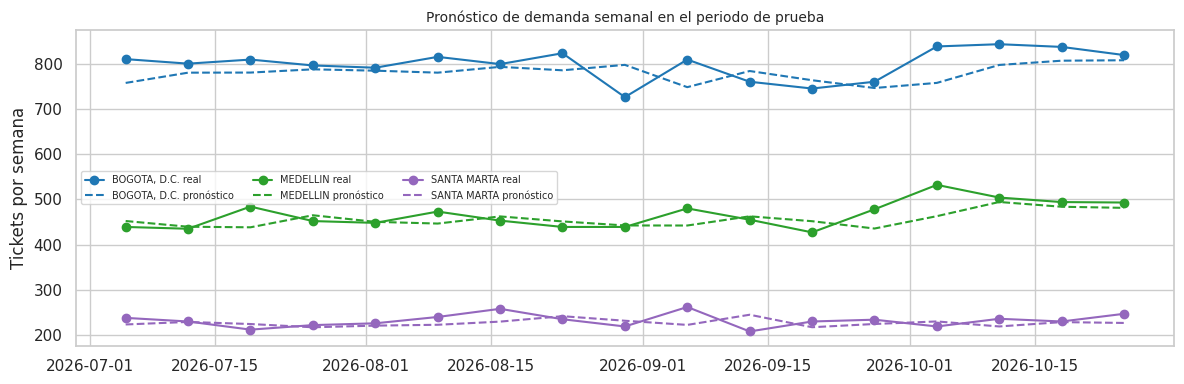

In [38]:
print('=== TRADUCCIÓN OPERATIVA: POLÍTICA DE DESPACHO DE REPUESTOS ===')
politicas = []
for umbral in [0.3, 0.4, 0.5, 0.7, 0.8]:
    lleva = prob_rep_test >= umbral
    politicas.append({
        'Umbral de probabilidad': umbral,
        '% de visitas despachadas con repuesto': lleva.mean() * 100,
        '% de visitas con necesidad cubierta (recall)': recall_score(y_te_rep, lleva) * 100,
        '% de repuestos llevados que se usan (precision)': precision_score(y_te_rep, lleva) * 100,
        'Visitas que necesitaban repuesto y no lo llevaban': int(((~lleva) & (y_te_rep == 1)).sum()),
    })
display(pd.DataFrame(politicas).set_index('Umbral de probabilidad').round(1))
print(f"Referencia sin modelo: llevar repuesto siempre cubre el 100 % con una tasa de uso de "
      f"{y_te_rep.mean():.1%}; no llevarlo nunca deja sin cubrir {int(y_te_rep.sum()):,} visitas.")

fig, eje = plt.subplots(figsize=(12, 4))
semanas_test = semanal.loc[es_te]
for ciudad, color in zip(['BOGOTA, D.C.', 'MEDELLIN', 'SANTA MARTA'], ['tab:blue', 'tab:green', 'tab:purple']):
    filtro = semanas_test['CIUDAD'] == ciudad
    eje.plot(semanas_test.loc[filtro, 'semana'], semanas_test.loc[filtro, 'tickets'], marker='o', color=color,
             label=f'{ciudad} real')
    eje.plot(semanas_test.loc[filtro, 'semana'], pred_demanda_test[filtro.values], linestyle='--', color=color,
             label=f'{ciudad} pronóstico')
eje.set_title('Pronóstico de demanda semanal en el periodo de prueba', fontsize=10)
eje.set_ylabel('Tickets por semana')
eje.legend(fontsize=7, ncol=3)
plt.tight_layout()
plt.show()

* **Sin modelo**, las opciones son extremas. Llevar repuesto siempre cubre todas las visitas, pero solo el 53,5 % de los repuestos se usa. No llevarlo nunca deja 16.786 visitas de prueba sin el repuesto que necesitaban.
* Con el modelo y un **umbral de 0,4**, se despacha repuesto en el 61,7 % de las visitas, se cubre el 86,2 % de las que lo necesitan y el 74,7 % de los repuestos transportados se usa. Frente a llevar siempre, la tasa de uso del inventario sube 21 puntos, a cambio de dejar sin cubrir 2.315 visitas (14 % de las que necesitaban repuesto).
* Con un **umbral de 0,3**, la cobertura llega al 98,3 % (solo 292 visitas sin repuesto) y el uso del inventario, al 65,5 %. Es la opción recomendable si una visita fallida es mucho más costosa que transportar un repuesto, que es lo usual cuando el comercio queda sin poder cobrar.
* El gráfico de demanda muestra que el pronóstico de Ridge sigue el nivel y las variaciones de cada ciudad durante el periodo de prueba. Es una base suficiente para planear la asignación semanal de técnicos con un error cercano al 5 %.

## 13.1 **Exportación de Artefactos para la Fase 4**

Guardamos los modelos entrenados y la tabla de segmentación de comercios para usarlos en el dashboard interactivo de la Fase 4 (módulo de predicción en vivo y mapa de clústeres). También imprimimos las versiones de las librerías del entorno, que se registran en el requirements.txt del repositorio.

In [39]:
import joblib
import sklearn

os.makedirs('artefactos', exist_ok=True)
joblib.dump(mejor_modelo_rep, 'artefactos/modelo_requiere_repuesto.joblib')
joblib.dump(modelo_tipo, 'artefactos/modelo_tipo_falla.joblib')
joblib.dump(modelo_gb_reg, 'artefactos/modelo_dias_resolucion.joblib')
tabla_comercios.to_csv('artefactos/segmentacion_comercios.csv')
print('Artefactos guardados en la carpeta artefactos/ para el dashboard de la Fase 4:')
for archivo in sorted(os.listdir('artefactos')):
    print(f"  {archivo:<40} {os.path.getsize(os.path.join('artefactos', archivo)) / 1e6:6.1f} MB")

print('\nVersiones para requirements.txt:')
for libreria in [pd, np, sklearn, sns, joblib]:
    print(f"  {libreria.__name__}=={libreria.__version__}")
if TORCH_DISPONIBLE:
    print(f"  torch=={torch.__version__}")

Artefactos guardados en la carpeta artefactos/ para el dashboard de la Fase 4:
  modelo_dias_resolucion.joblib               0.4 MB
  modelo_requiere_repuesto.joblib             3.6 MB
  modelo_tipo_falla.joblib                   27.9 MB
  segmentacion_comercios.csv                  0.2 MB

Versiones para requirements.txt:
  pandas==2.2.3
  numpy==2.4.6
  sklearn==1.9.1
  seaborn==0.13.2
  joblib==1.6.0
  torch==2.14.1+cu130


# 14. Discusión y Conclusiones

## 14.1 **Respuesta a las Preguntas de Investigación**

**Pregunta principal.** Con la información disponible al abrir un ticket es posible anticipar con utilidad operativa tres de las cuatro decisiones logísticas:
* la necesidad de repuesto (AUC 0,84);
* el tiempo de resolución, con un error medio de 3 días, un tercio menos que sin modelo;
* la demanda semanal por ciudad, con un error cercano al 5 %.

La cuarta decisión, el tipo exacto de falla, solo es parcialmente predecible (32 % de exactitud). Aun así, es útil como recomendación de las tres fallas más probables, que cubre el 62 % de los casos. La segmentación identifica tres perfiles de comercio con estrategias preventivas diferenciadas.

**Pregunta secundaria 1.** La tecnología de conectividad y el modelo de equipo son los determinantes del tipo de falla. El tipo de falla reportado determina casi por completo la necesidad de repuesto. El tiempo de resolución depende sobre todo del tipo de falla y, en segundo lugar, del técnico y la ciudad.

**Pregunta secundaria 2.** La demanda tiene estacionalidad semanal (el domingo cae a menos de la mitad), un pico anual en diciembre y una tendencia creciente en 2026. Un modelo Ridge con rezagos la pronostica una semana adelante con un MAE de 18,8 tickets por ciudad, un 12 % menos que el pronóstico ingenuo.

**Pregunta secundaria 3.** Emergen tres segmentos: comercios con fallas de hardware, comercios con conectividad inalámbrica y grandes cuentas. Las grandes cuentas son apenas el 11 % de los comercios, pero concentran el 46 % de los tickets y son la prioridad del mantenimiento preventivo.

## 14.2 **Hallazgos Metodológicos**

1. **La calidad de los datos determinó el alcance del proyecto.** La primera versión del dataset, con registros triplicados y variables independientes, no permitía ningún modelo útil. La versión actual permitió reformular el problema. La eliminación de duplicados antes de partir los datos sigue siendo indispensable para evitar métricas infladas por memorización.
2. **El modelo más complejo no siempre es el mejor.** En la predicción de repuestos y de tipo de falla, la regresión logística, los árboles y el perceptrón multicapa llegan al mismo desempeño. En el pronóstico de demanda, el modelo lineal supera al ensamble. El techo lo fija la información disponible y no la capacidad del algoritmo.
3. **La métrica debe reflejar la decisión.** Cambiar la exactitud por la exactitud top-3 y fijar el umbral de despacho según su costo convirtió resultados modestos en recomendaciones aplicables.

## 14.3 **Limitaciones**

* Los datos están anonimizados y las conclusiones deben validarse con datos de la operación antes de implementarse.
* La partición a nivel de ticket es aleatoria y estratificada, como pide la guía. En producción, el modelo se aplicaría a tickets futuros, por lo que conviene revalidarlo con una partición temporal.
* El costo de una visita fallida y el de un repuesto inmovilizado no están en los datos. El umbral de despacho recomendado debe ajustarse con esos costos reales.
* El impacto de las estrategias preventivas por segmento no puede medirse dentro del proyecto. Requiere una prueba piloto en campo.


# 14. Referencias Bibliográficas

* Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32.
* Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
* Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2nd ed.). Springer.
* Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/
* Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1-21.
* Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection: A Practical Approach for Predictive Models*. CRC Press.
* Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.
* Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765-4774.
* Paszke, A., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*, 8024-8035.
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
* Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65.
* Rojas Ordóñez, S. A. (2026). *Proyecto_CIENCIA_DE_DATOS_G2: Conjunto de datos de soporte técnico de datáfonos* [Repositorio de código y datos]. GitHub. https://github.com/sergiorojas-oss/Proyecto_CIENCIA_DE_DATOS_G2
* Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301-320.